# DEMOSTRACIONES PARA BONO ML Juan Oñoro

## Alcance y organización

Este documento resuelve completas las 8 demostraciones de la tarea: dos de K-NN, tres de Ridge, una de Lasso, la revisión del árbol de decisión y la de AdaBoost. Los datos del árbol se tomaron de la Tabla 5.1 de las notas del curso.

Cada demostración sigue el mismo orden: qué se pide, para qué sirve, intuición con una analogía de ingeniería, desarrollo paso a paso, comprobación numérica y errores comunes. En el desarrollo, cada paso indica su **objetivo** (qué se busca con él) y su **justificación** (por qué es válido).

| **N.º** | **Tema** | **Qué se demuestra** | **Resultado clave** |
|-----|------------|-------------------------|--------------------------------|
| 1 | K-NN | Desarrollo del error verdadero $L_{\mathcal{D}}(h)$, ec. 2.2 | $L_{\mathcal{D}}(h)$ es la probabilidad de fallar con un dato nuevo; el mínimo posible es $\mathbb{E}\left\lbrack \min\{\eta,1 - \eta\} \right\rbrack$ |
| 2 | K-NN | Caso $\min\{\eta,1 - \eta\} = 1 - \eta$ de la desigualdad del Lema 2.1 | 1-NN falla, en promedio, como máximo el doble del error óptimo más un término de distancia |
| 3 | Ridge | Igualdades de la estandarización, ec. 3.11 | Columnas con suma 0 y suma de cuadrados $n$; el intercepto queda en 0 |
| 4 | Ridge | $Z^{T}\mathbf{1} = \mathbf{1}^{T}Z = 0$ y derivada 3.8 | Intercepto y pendientes se desacoplan; ${\widehat{\beta}}_{s} = \left( Z^{T}Z + \lambda I \right)^{- 1}Z^{T}y$ |
| 5 | Ridge | Esperanza, covarianza, sesgo y ECM, ec. 3.12 | Ridge cambia un poco de sesgo por mucha menos varianza |
| 6 | Lasso | Estimación de parámetros y algoritmo LARS | Umbral suave: los coeficientes pequeños quedan exactamente en cero |
| 7 | Árbol de decisión | Error de la solución publicada del Ejercicio 6 | El segundo nodo debió ser Age \< 49 (Gini 0), no Like Dogs |
| 8 | AdaBoost | Origen de $a_{i}$, de los pesos y de $Z_{i}$; Algoritmo 5.1 | Todo sale de minimizar la pérdida exponencial, una ronda a la vez |

Las tres demostraciones de Ridge se presentan en orden lógico (3.11, luego 3.8, luego 3.12) y no en el orden de la tarea, porque cada una usa el resultado de la anterior.

### Notación común

| **Símbolo** | **Significado** | **Lectura en ingeniería** |
|---------|------------------------------|---------------------------------|
| $P\lbrack A\rbrack$ | Probabilidad del evento $A$, entre 0 y 1 | Fracción de veces que ocurre $A$ en un proceso repetido |
| $\mathbb{E}\lbrack X\rbrack$ | Esperanza: promedio de $X$ en infinitas repeticiones | Valor medio de una medición repetida |
| $Var$, $Cov$ | Varianza y covarianza | Dispersión de una medida y cómo varían juntas dos medidas |
| $A^{T}$, $A^{- 1}$ | Traspuesta e inversa de $A$ | Igual que en el método matricial de estructuras |
| $I_{p}$ | Matriz identidad $p \times p$ | Actúa como el número 1 |
| $\mathbf{1}$ | Vector columna de $n$ unos | Multiplicar por él equivale a sumar |
| $\mathbb{I}\lbrack A\rbrack$ | Indicadora: vale 1 si $A$ ocurre y 0 si no | Una alarma que se enciende cuando hay error |
| $\arg\min $ | El argumento que minimiza, no el valor mínimo | El diseño óptimo, no el costo óptimo |
| $: =$ | Se define como | Una definición, no un resultado |
| $\star$ | Superíndice de óptimo o de modelo centrado ($h^{\star}$, $\beta_{0}^{\star}$) | Se escribe como estrella, no como producto |

Las notas escriben los vectores en negrita; aquí se escriben con letra normal y el contexto indica si son vectores. Los párrafos marcados como **Observación sobre las notas** señalan diferencias entre las notas publicadas y lo que la matemática exige.

## Demostración 1. K-NN: el error verdadero $L_{\mathcal{D}}\left( h \right)$

La ecuación 2.2 define el error verdadero como la probabilidad de que el clasificador $h$ falle con un dato nuevo. Desarrollarla lleva a una forma con $\eta(x)$ y muestra que ningún clasificador puede bajar de $\mathbb{E}\left\lbrack \min\{\eta(x),1 - \eta(x)\} \right\rbrack$.

### Qué se pide

Desarrollar paso a paso la ecuación 2.2 de la Definición 2.3:

$$L_{\mathcal{D}}(h): = \mathbb{P}_{(x,y) \sim \mathcal{D}}\left\lbrack h(x) \neq y \right\rbrack: = \mathcal{D}\left( \{(x,y):\ h(x) \neq y\} \right)$$

### Para qué sirve

$L_{\mathcal{D}}(h)$ mide lo que de verdad importa: el desempeño del modelo en operación, con datos que nunca vio. El desarrollo sirve para tres cosas: entender que el error de entrenamiento $L_{S}(h)$ es solo un estimador de $L_{\mathcal{D}}(h)$; obtener la expresión con $\eta(x)$ que usa la Demostración 2; e identificar el mejor clasificador posible (Bayes), la referencia contra la que se compara K-NN.

### Intuición

Piensa en una línea de producción. Cada pieza trae mediciones $x$ (diámetro, dureza, rugosidad) y un estado real $y$: conforme (0) o defectuosa (1). El proceso de manufactura es $\mathcal{D}$: decide qué piezas salen y con qué frecuencia, y nadie conoce su receta exacta. Un criterio automático de aceptación $h$ mira $x$ y decide.

El error verdadero responde una sola pregunta: si sale la siguiente pieza, ¿con qué probabilidad el criterio se equivoca, ya sea rechazando una buena o aceptando una defectuosa? La ecuación lo dice de dos formas: como probabilidad del evento “el criterio falla” y como la masa de probabilidad que cae sobre la región de error, igual que la masa de un cuerpo es la integral de su densidad sobre el volumen que ocupa.

### Símbolos

| **Símbolo** | **Qué es** | **En la analogía** |
|----------------|----------------------|-----------------------------------|
| $\mathcal{X}$ | Espacio de entradas | Todas las combinaciones posibles de mediciones |
| $\mathcal{Y} = \{ 0,1\}$ | Etiquetas posibles | Conforme o defectuosa |
| $\mathcal{D}$ | Distribución conjunta de $(x,y)$ | El proceso de manufactura |
| $\mathcal{D}_{x}$ | Distribución marginal de $x$ | Qué tan frecuente es cada combinación de mediciones |
| $h(x)$ | Predicción del modelo | Decisión del criterio de aceptación |
| $\eta(x): = P(y = 1 \mid x)$ | Probabilidad de clase 1 dado $x$ | Fracción defectuosa entre las piezas con mediciones $x$ |
| $\mathbb{I}\lbrack \cdot \rbrack$ | Indicadora | Alarma que vale 1 cuando hay error |

### Desarrollo paso a paso

**Paso 1. Definir la región de error.**

Objetivo: convertir “el modelo falla” en un objeto matemático concreto al que se le pueda asignar probabilidad.

$$A_{h} = \{(x,y) \in \mathcal{X} \times \mathcal{Y}:\ h(x) \neq y\}$$

Justificación: en probabilidad, un evento es un subconjunto del espacio de resultados. $A_{h}$ reúne todas las parejas donde $h$ se equivoca; es un conjunto, no un número.

**Paso 2. Igualar las dos escrituras de la ecuación 2.2.**

Objetivo: demostrar la segunda igualdad de 2.2.

$$L_{\mathcal{D}}(h) = \mathbb{P}_{(x,y) \sim \mathcal{D}}\left\lbrack (x,y) \in A_{h} \right\rbrack = \mathcal{D}\left( A_{h} \right)$$

Justificación: “$h$ falla” equivale a “la pareja cae en $A_{h}$”, y la probabilidad de caer en un conjunto es, por definición, la medida $\mathcal{D}$ de ese conjunto.

**Paso 3. Escribir la probabilidad como un promedio.**

Objetivo: pasar de una probabilidad a una esperanza, que se puede escribir como suma o integral y que conecta con la pérdida 0-1.

$$\mathbb{I}\left\lbrack h(x) \neq y \right\rbrack = \left\{ \begin{matrix}
1 & h(x) \neq y \\
0 & h(x) = y
\end{matrix} \right. \quad\quad \Rightarrow \quad\quad L_{\mathcal{D}}(h) = \mathbb{E}_{(x,y) \sim \mathcal{D}}\left\lbrack \mathbb{I}\left\lbrack h(x) \neq y \right\rbrack \right\rbrack$$

Justificación: para una variable $\alpha$ que solo vale 0 o 1, $\mathbb{E}\lbrack\alpha\rbrack = 0 \cdot P\lbrack\alpha = 0\rbrack + 1 \cdot P\lbrack\alpha = 1\rbrack = P\lbrack\alpha = 1\rbrack$. Si la alarma se enciende en 3 de cada 10 piezas, su promedio es 0.3. A $\mathbb{I}\left\lbrack h(x) \neq y \right\rbrack$ se le llama pérdida 0-1 (acertar cuesta 0, fallar cuesta 1), y así se ve que 2.2 es el caso particular de la ecuación 2.4 con esa pérdida.

**Paso 4. Escribir la esperanza como suma o integral.**

Objetivo: tener una expresión que se podría evaluar si se conociera $\mathcal{D}$.

$$L_{\mathcal{D}}(h) = \sum_{(x,y)}^{}\mathcal{D}(x,y)\,\mathbb{I}\left\lbrack h(x) \neq y \right\rbrack\quad\text{(caso discreto)}$$

$$L_{\mathcal{D}}(h) = \sum_{y \in \{ 0,1\}}^{}{\int_{\mathcal{X}}^{}p}(x,y)\,\mathbb{I}\left\lbrack h(x) \neq y \right\rbrack\, dx\quad\text{(caso continuo)}$$

Justificación: es la definición de esperanza. Las parejas acertadas se multiplican por 0 y desaparecen; solo se suma la probabilidad de las parejas con error.

**Paso 5. Separar qué pieza llega de qué estado tiene.**

Objetivo: aislar el error que se comete en cada punto $x$, porque K-NN trabaja punto a punto en $\mathcal{X}$.

$$\mathcal{D}(x,y) = \mathcal{D}_{x}(x)\, P(y \mid x)\quad \Rightarrow \quad L_{\mathcal{D}}(h) = \sum_{x}^{}\mathcal{D}_{x}(x)\sum_{y}^{}P(y \mid x)\,\mathbb{I}\left\lbrack h(x) \neq y \right\rbrack = \mathbb{E}_{x \sim \mathcal{D}_{x}}\left\lbrack P\left( y \neq h(x) \mid x \right) \right\rbrack$$

Justificación: regla del producto. Primero sale una pieza con mediciones $x$ y después su estado $y$ se sortea con $P(y \mid x)$. La suma interior es el error con las piezas de tipo $x$; el error total es su promedio ponderado por la frecuencia de cada tipo.

**Paso 6. Introducir** $\eta(x)$ **en el caso binario.**

Objetivo: escribir el error con una sola función, $\eta(x)$, que es la que aparece en el Lema 2.1.

$$\eta(x): = P(y = 1 \mid x),\quad\quad P\left( y \neq h(x) \mid x \right) = \left\{ \begin{matrix}
1 - \eta(x) & h(x) = 1 \\
\eta(x) & h(x) = 0
\end{matrix} \right.$$

$$L_{\mathcal{D}}(h) = \mathbb{E}_{x}\left\lbrack \eta(x)\,\mathbb{I}\left\lbrack h(x) = 0 \right\rbrack + \left( 1 - \eta(x) \right)\,\mathbb{I}\left\lbrack h(x) = 1 \right\rbrack \right\rbrack$$

Justificación: si el criterio dice “defectuosa” (1), falla con las conformes, que son la fracción $1 - \eta(x)$; si dice “conforme” (0), falla con las defectuosas, que son la fracción $\eta(x)$.

**Paso 7. Obtener el mejor clasificador posible (predictor óptimo de Bayes, ecuación 2.3).**

Objetivo: encontrar el $h$ que minimiza $L_{\mathcal{D}}(h)$, que será la cota inferior de cualquier modelo.

$$h^{\star}(x) = \left\{ \begin{matrix}
1 & \eta(x) \geq 1/2 \\
0 & \eta(x) < 1/2
\end{matrix} \right. \quad\quad \Rightarrow \quad\quad L_{\mathcal{D}}\left( h^{\star} \right) = \mathbb{E}_{x}\left\lbrack \min\{\eta(x),\, 1 - \eta(x)\} \right\rbrack$$

Justificación: en el Paso 6, para cada $x$ se paga $\eta(x)$ o $1 - \eta(x)$ según la decisión. Como cada $x$ se decide por separado, lo óptimo es pagar siempre el menor, es decir, predecir la clase más probable. En el empate $\eta = 1/2$ las dos decisiones cuestan lo mismo, así que da igual a qué clase se asigne. Este piso viene del ruido propio del proceso: dos piezas con las mismas mediciones pueden tener estados distintos, y ningún modelo lo elimina.

**Paso 8. Conectar con lo que sí se puede medir: el error empírico.**

Objetivo: justificar por qué se usa $L_{S}(h)$ para estimar $L_{\mathcal{D}}(h)$ y cuándo esa estimación es honesta.

$$L_{S}(h) = \frac{1}{m}\sum_{i = 1}^{m}\mathbb{I}\left\lbrack h\left( x_{i} \right) \neq y_{i} \right\rbrack,\quad\quad\mathbb{E}_{S \sim \mathcal{D}^{m}}\left\lbrack L_{S}(h) \right\rbrack = \frac{1}{m}\sum_{i = 1}^{m}\mathbb{E}\left\lbrack \mathbb{I}\left\lbrack h\left( x_{i} \right) \neq y_{i} \right\rbrack \right\rbrack = \frac{1}{m} \cdot m \cdot L_{\mathcal{D}}(h) = L_{\mathcal{D}}(h)$$

Justificación: linealidad de la esperanza, y cada dato de $S$ sale del mismo proceso $\mathcal{D}$ de forma independiente, así que cada término vale $L_{\mathcal{D}}(h)$. Es un estimador insesgado, igual que la fracción defectuosa de un lote estima la del proceso. La condición es que $h$ sea fijo, elegido sin mirar $S$. Si $h$ se ajustó con $S$, $L_{S}(h)$ resulta optimista; 1-NN es el caso extremo, con $L_{S}(h) = 0$ sobre su propio entrenamiento.

### Comprobación numérica

Un proceso con dos tipos de pieza, $a$ y $b$, y un criterio que decide $h(a) = 0$ y $h(b) = 1$:

| $(x,y)$ | $\mathcal{D}(x,y)$ | $h(x)$ | **¿Error?** |
|-----------|----------------------|----------|-------------|
| $(a,0)$ | 0.3                  | 0        | No          |
| $(a,1)$ | 0.1                  | 0        | Sí          |
| $(b,0)$ | 0.2                  | 1        | Sí          |
| $(b,1)$ | 0.4                  | 1        | No          |

1.  Con el Paso 4: $L_{\mathcal{D}}(h) = 0.1 + 0.2 = 0.3$.
2.  Con el Paso 6: $\mathcal{D}_{x}(a) = 0.4$ y $\eta(a) = 0.1/0.4 = 0.25$; $\mathcal{D}_{x}(b) = 0.6$ y $\eta(b) = 0.4/0.6 \approx 0.667$. Entonces $L_{\mathcal{D}}(h) = 0.4 \times 0.25 + 0.6 \times (1 - 0.667) = 0.1 + 0.2 = 0.3$.
3.  Con el Paso 7: $\eta(a) < 1/2$ lleva a 0 y $\eta(b) \geq 1/2$ lleva a 1. Este $h$ coincide con el de Bayes, así que 0.3 es el menor error alcanzable con este proceso.

### Errores comunes

1.  Confundir $L_{\mathcal{D}}(h)$ con $L_{S}(h)$. El primero es una propiedad del proceso y no se puede calcular porque $\mathcal{D}$ es desconocida; el segundo se mide con los datos.
2.  Creer que un buen modelo puede llegar a error cero. Si las clases se traslapan ($\eta(x)$ distinto de 0 y de 1), el piso $\mathbb{E}\left\lbrack \min\{\eta,1 - \eta\} \right\rbrack$ es mayor que cero.
3.  Reportar como $L_{\mathcal{D}}(h)$ el error medido sobre los mismos datos de entrenamiento. Con K-NN esto es especialmente engañoso.

**Observación sobre las notas.** Al afirmar que el predictor de Bayes es óptimo, las notas escriben “ningún otro clasificador $g:\  \rightarrow \{ 0,1\}$”. Falta el dominio: debe ser $g:\mathcal{X} \rightarrow \{ 0,1\}$.

## Demostración 2. K-NN: el caso $\min\{\eta,1-\eta\} =1-\eta$ del Lema 2.1

En el caso $\eta(x) \geq 1/2$, la desigualdad $2\eta(1 - \eta) \leq 2\min\{\eta,1 - \eta\}$ se cumple porque $\eta \leq 1$, y con ella se cierra el Lema 2.1: $\mathbb{E}\left\lbrack L_{\mathcal{D}}\left( h_{S} \right) \right\rbrack \leq 2L_{\mathcal{D}}\left( h^{\star} \right) + c\,\mathbb{E} \parallel x - x' \parallel$. Además, la cadena que aparece en las notas para el caso ya visto tiene un paso falso; aquí se da la versión correcta.

### Qué se pide

En clase se demostró el caso $\min\{\eta(x),1 - \eta(x)\} = \eta(x)$. Falta el caso $\min\{\eta(x),1 - \eta(x)\} = 1 - \eta(x)$, para concluir:

$$2\eta(x)\left( 1 - \eta(x) \right) \leq 2\min\{\eta(x),\, 1 - \eta(x)\}\quad \Rightarrow \quad\mathbb{E}_{S \sim \mathcal{D}^{m}}\left\lbrack L_{\mathcal{D}}\left( h_{S} \right) \right\rbrack \leq 2L_{\mathcal{D}}\left( h^{\star} \right) + c\,\mathbb{E}\lbrack \parallel x - x' \parallel \rbrack$$

### Para qué sirve

El Lema 2.1 responde qué tan malo puede ser 1-NN, un método que no aprende parámetros y solo compara. La respuesta es que, en promedio, falla como máximo el doble que el mejor clasificador posible, más un término que depende de la distancia al vecino. La desigualdad de este ejercicio es el paso puente: convierte $2\eta(1 - \eta)$, que sale de dos sorteos independientes, en $2L_{\mathcal{D}}\left( h^{\star} \right)$, el doble del error de Bayes.

### Intuición

1-NN equivale a evaluar una pieza nueva buscando en la base de datos la pieza ya inspeccionada más parecida y copiando su veredicto. El error tiene dos fuentes.

1.  Ruido del proceso. Aunque el vecino fuera idéntico, su estado y el de la pieza nueva son dos sorteos independientes; la probabilidad de que no coincidan es $2\eta(1 - \eta)$, que es como máximo el doble del error de Bayes. De ahí sale el factor 2.
2.  El vecino no es idéntico. $\eta$ cambia entre $x$ y $x'$. Si $\eta$ es $c$-Lipschitz, se comporta como un campo suave con gradiente acotado por $c$ (por ejemplo, un campo de temperatura sin saltos), y el cambio es como máximo $c \parallel x - x' \parallel$. Con más datos el vecino está más cerca, igual que el error de discretización baja al refinar una malla de elementos finitos.

### Símbolos y supuestos

| **Símbolo** | **Qué es** |
|----------|--------------------------------------------------------------|
| $h_{S}$ | Clasificador 1-NN construido con la muestra $S$ |
| $x'$, $y'$ | Vecino más cercano de $x$ en $S$ y su etiqueta; las notas los escriben $x_{\pi_{1}(x)}$ y $y_{\pi_{1}(x)}$ |
| $\eta(x)$ | $P(y = 1 \mid x)$ |
| $h^{\star}$ | Clasificador óptimo de Bayes (Demostración 1, Paso 7) |
| $c$ | Constante de Lipschitz de $\eta$: $|\eta(x) - \eta(x')| \leq c \parallel x - x' \parallel$ |
| $\parallel x - x' \parallel$ | Distancia euclidiana entre $x$ y su vecino |

Supuestos del Lema 2.1: $\mathcal{X} = \lbrack 0,1\rbrack^{d}$, $\mathcal{Y} = \{ 0,1\}$, distancia euclidiana, $S$ muestra iid de tamaño $m$ y $\eta$ $c$-Lipschitz.

### Desarrollo paso a paso

Los pasos 1 a 4 reconstruyen de dónde sale $2\eta(1 - \eta)$; los pasos 5 a 8 son el ejercicio; los pasos 9 a 11 completan el lema.

**Paso 1. Escribir el error de 1-NN como probabilidad de desacuerdo.**

Objetivo: expresar el error de 1-NN solo con las etiquetas de $x$ y de su vecino.

$$\mathbb{E}_{S}\left\lbrack L_{\mathcal{D}}\left( h_{S} \right) \right\rbrack = \mathbb{E}_{S_{x},\, x}\left\lbrack \,\mathbb{P}(y \neq y')\, \right\rbrack$$

Justificación: 1-NN predice $y'$, la etiqueta del vecino, y falla exactamente cuando $y \neq y'$.

**Paso 2. Calcular la probabilidad de desacuerdo.**

Objetivo: escribir $\mathbb{P}(y \neq y')$ en función de $\eta$.

$$\mathbb{P}(y \neq y') = \eta(x')\left( 1 - \eta(x) \right) + \left( 1 - \eta(x') \right)\eta(x)$$

Justificación: hay dos formas disjuntas de desacuerdo (vecino 1 y pieza 0, o vecino 0 y pieza 1), y los dos sorteos son independientes, así que cada probabilidad es un producto.

**Paso 3. Separar lo que depende de** $x$ **de la diferencia con el vecino.**

Objetivo: que aparezca el término $2\eta(x)\left( 1 - \eta(x) \right)$, que solo depende de $x$.

$$\delta: = \eta(x') - \eta(x)\quad \Rightarrow \quad(\eta + \delta)(1 - \eta) + (1 - \eta - \delta)\eta = 2\eta(1 - \eta) + \delta(1 - 2\eta)$$

$$\mathbb{P}(y \neq y') = 2\eta(x)\left( 1 - \eta(x) \right) + \left( \eta(x) - \eta(x') \right)\left( 2\eta(x) - 1 \right)$$

Justificación: se escribe $\eta(x')$ como $\eta(x)$ más una perturbación $\delta$, se expande y se reagrupa. Es la misma idea que linealizar alrededor de un punto de operación: valor nominal más desviación.

**Paso 4. Acotar el término de la diferencia.**

Objetivo: reemplazar la diferencia entre $\eta(x)$ y $\eta(x')$ por algo geométrico, la distancia entre puntos.

$$\mathbb{P}(y \neq y') \leq 2\eta(x)\left( 1 - \eta(x) \right) + |\eta(x) - \eta(x')|\,|2\eta(x) - 1| \leq 2\eta(x)\left( 1 - \eta(x) \right) + c \parallel x - x' \parallel$$

Justificación: una probabilidad es no negativa, así que es igual a su valor absoluto y se puede usar la desigualdad triangular $|a + b| \leq |a| + |b|$. Como $0 \leq \eta \leq 1$, se tiene $- 1 \leq 2\eta - 1 \leq 1$, es decir $|2\eta - 1| \leq 1$. La condición de Lipschitz da $|\eta(x) - \eta(x')| \leq c \parallel x - x' \parallel$.

**Paso 5. Traducir la hipótesis del caso (inicio del ejercicio).**

Objetivo: saber qué información aporta el caso. Para aligerar la notación se escribe $\eta$ en lugar de $\eta(x)$.

$$\min\{\eta,\, 1 - \eta\} = 1 - \eta\quad \Rightarrow \quad 1 - \eta \leq \eta\quad \Rightarrow \quad\eta \geq \frac{1}{2}$$

Justificación: el mínimo es el menor de los dos números.

**Paso 6. Reunir los dos hechos que se necesitan.**

Objetivo: tener a mano las únicas herramientas de la prueba.

$$0 \leq 1 - \eta\quad\quad\text{y}\quad\quad\eta \leq 1$$

Justificación: ambos salen de que $\eta$ es una probabilidad, $\eta \in \lbrack 0,1\rbrack$.

**Paso 7. Acotar el factor grande por 1.**

Objetivo: eliminar el factor $\eta$, que en este caso es el mayor, para que solo quede el mínimo.

$$2\eta(1 - \eta)\  \leq \ 2 \cdot 1 \cdot (1 - \eta) = 2(1 - \eta)$$

Justificación: se parte de $\eta \leq 1$ y se multiplican ambos lados por $2(1 - \eta)$. Como esa cantidad es mayor o igual a cero (Paso 6), la desigualdad no cambia de sentido.

**Paso 8. Identificar el mínimo.**

Objetivo: cerrar el caso.

$$2(1 - \eta) = 2\min\{\eta,\, 1 - \eta\}\quad\quad$$

Justificación: por la hipótesis del caso, $1 - \eta$ es justamente el mínimo. La desigualdad del Paso 7 vale para cualquier $\eta \in \lbrack 0,1\rbrack$; la hipótesis $\eta \geq 1/2$ solo se usa aquí, para reconocer $2(1 - \eta)$ como $2\min\{\eta,1 - \eta\}$.

**Paso 9. El caso visto en clase, escrito correctamente.**

Objetivo: dejar los dos casos con el mismo argumento, en espejo.

$$\min\{\eta,\, 1 - \eta\} = \eta\quad \Rightarrow \quad 2\eta(1 - \eta) \leq 2\,\eta \cdot 1 = 2\eta = 2\min\{\eta,\, 1 - \eta\}$$

Justificación: ahora se acota el otro factor, $1 - \eta \leq 1$, multiplicando por $2\eta \geq 0$.

**Paso 10. Versión de una línea que cubre ambos casos.**

Objetivo: ver la idea completa sin separar casos.

$$\eta(1 - \eta) = \min\{\eta,1 - \eta\} \cdot \max\{\eta,1 - \eta\} \leq \min\{\eta,1 - \eta\} \cdot 1$$

Justificación: el producto de dos números es el menor por el mayor, y el mayor es como máximo 1.

**Paso 11. Cerrar el Lema 2.1.**

Objetivo: pasar de la desigualdad punto a punto a la cota del error promedio.

$$\mathbb{E}_{S}\left\lbrack L_{\mathcal{D}}\left( h_{S} \right) \right\rbrack \leq \mathbb{E}_{x}\left\lbrack 2\min\{\eta(x),1 - \eta(x)\} \right\rbrack + c\,\mathbb{E}\lbrack \parallel x - x' \parallel \rbrack = 2L_{\mathcal{D}}\left( h^{\star} \right) + c\,\mathbb{E}\lbrack \parallel x - x' \parallel \rbrack$$

Justificación: se toma esperanza en el Paso 4. La esperanza conserva las desigualdades (si $A \leq B$ en cada punto, $\mathbb{E}\lbrack A\rbrack \leq \mathbb{E}\lbrack B\rbrack$) y es lineal. Por la Demostración 1, $\mathbb{E}_{x}\left\lbrack \min\{\eta,1 - \eta\} \right\rbrack$ es exactamente $L_{\mathcal{D}}\left( h^{\star} \right)$.

### Comprobación numérica

| $\eta$ | $2\eta(1 - \eta)$ | $\min\{\eta,1 - \eta\}$ | $2\min$ | **¿Se cumple?** | **Caso** |
|------|-------------|----------------|--------|----------------|---------------|
| 0.1 | 0.18 | 0.1 | 0.20 | Sí | $\min = \eta$ |
| 0.3 | 0.42 | 0.3 | 0.60 | Sí | $\min = \eta$ |
| 0.5 | 0.50 | 0.5 | 1.00 | Sí | Ambos |
| 0.7 | 0.42 | 0.3 | 0.60 | Sí | $\min = 1 - \eta$ |
| 0.9 | 0.18 | 0.1 | 0.20 | Sí | $\min = 1 - \eta$ |

La tabla es simétrica alrededor de $\eta = 0.5$: $\eta = 0.7$ se comporta igual que $\eta = 0.3$. Por eso los dos casos se demuestran con el mismo argumento en espejo.

### Errores comunes

1.  Multiplicar una desigualdad por una cantidad sin verificar que sea no negativa. Aquí funciona porque $2\eta$ y $2(1 - \eta)$ son mayores o iguales a cero.
2.  Pensar que el factor 2 es un artificio algebraico. Viene de que hay dos sorteos inciertos: el de la pieza nueva y el de su vecino.
3.  Aplicar el lema cuando $\eta$ cambia de golpe. Un límite de tolerancia duro, por ejemplo, crea un salto en $\eta$; cerca de él, $\eta$ no es Lipschitz y el término de distancia deja de estar controlado.
4.  Leer la cota como una garantía para cada muestra. Es una cota en promedio, y en dimensión alta la distancia esperada al vecino baja muy despacio con $m$ (maldición de la dimensionalidad).

**Observación sobre las notas.** En la demostración publicada del Lema 2.1 hay cuatro detalles:

1.  Para el caso $\min = \eta$ aparece la cadena $2\eta(1 - \eta) \leq 2(1 - \eta)^{2} \leq 2\min\{\eta,1 - \eta\}$. El primer paso es válido, pero el segundo no: con $\eta = 0.2$ se obtiene $2(1 - \eta)^{2} = 1.28$, que no es menor que $2\min = 0.4$. La versión correcta es la del Paso 9.
2.  En la expansión de $\mathbb{P}(y \neq y')$, la tercera línea dice $\left( 1 - \eta(x')\eta(x) \right)$; falta un paréntesis y debe ser $\left( 1 - \eta(x') \right)\,\eta(x)$.
3.  Al mostrar que $|2\eta(x) - 1| \leq 1$, la cadena empieza “$0 \leq \eta(x) \leq 1 \leq \Leftrightarrow$”; sobra el $\leq$ antes de $\Leftrightarrow$.
4.  En las esperanzas finales aparecen $\mathcal{X} \sim \mathcal{D}_{x}$ y $\mathcal{D}_{x} \sim \mathcal{D}_{x}^{m}$. Lo que se sortea es el punto y la muestra, así que debe decir $x \sim \mathcal{D}_{x}$ y $S_{x} \sim \mathcal{D}_{x}^{m}$.

## Demostración 3. Ridge: igualdades de la estandarización (ec. 3.11)

Al centrar $y_{i}$ y estandarizar $x_{ij}$ con una desviación $s_{j}$ de divisor $n$, cada columna suma 0 y su suma de cuadrados vale $n$; en consecuencia, el intercepto del modelo centrado es $\beta_{0}^{\star} = \bar{y} = 0$. Las tres pruebas usan una sola herramienta: lo que no depende de $i$ sale de la suma.

### Qué se pide

Verificar que, al reemplazar $y_{i}$ por $y_{i} - \bar{y}$ y $x_{ij}$ por $\left( x_{ij} - {\bar{x}}_{j} \right)/s_{j}$, se cumple:

$$\sum_{i = 1}^{n}y_{i} = 0,\quad\quad\sum_{i = 1}^{n}x_{ij} = 0\ \ (j = 1,\ldots,p),\quad\quad\sum_{i = 1}^{n}x_{ij}^{2} = n,\quad\quad\beta_{0}^{\star} = \bar{y} = \frac{1}{n}\sum_{i = 1}^{n}y_{i} = 0$$

### Para qué sirve

Ridge y Lasso penalizan el tamaño de los coeficientes, y ese tamaño depende de las unidades de cada variable. Estandarizar pone a todas las variables en igualdad de condiciones, de modo que la penalización sea justa. Además elimina el intercepto del problema, de modo que solo quedan por estimar las pendientes, y deja $Z^{T}Z$ con diagonal igual a $n$, la escala que usan las Demostraciones 4, 5 y 6.

### Intuición

Estandarizar es adimensionalizar. Supongamos un modelo que predice vida a fatiga a partir de la amplitud de esfuerzo en MPa (valores entre 100 y 400) y de la rugosidad superficial en µm (valores entre 0.4 y 3.2). El coeficiente de la rugosidad sale numéricamente grande solo por sus unidades, y Ridge lo castigaría más sin razón física.

Centrar mueve el origen al punto de operación promedio, igual que medir respecto al centroide. Escalar divide entre una magnitud característica, $s_{j}$, igual que se define un número adimensional. Después de estandarizar, cada variable se mide en desviaciones estándar por encima o por debajo de su media.

### Símbolos

| **Símbolo** | **Qué es** |
|---------|---------------------------------------------------------------|
| $n$ | Número de observaciones (filas) |
| $p$ | Número de variables predictoras (columnas) |
| $x_{ij}$ | Valor de la variable $j$ en la observación $i$ |
| ${\bar{x}}_{j}$ | Media de la variable $j$: $\frac{1}{n}\sum_{i}^{}x_{ij}$ |
| $\bar{y}$ | Media de la respuesta: $\frac{1}{n}\sum_{i}^{}y_{i}$ |
| $s_{j}$ | Desviación estándar de la variable $j$, con $s_{j}^{2} = \frac{1}{n}\sum_{i}^{}\left( x_{ij} - {\bar{x}}_{j} \right)^{2}$ (divisor $n$, como en las notas antes de la ec. 3.4) |
| $\beta_{0}^{\star}$ | Intercepto del modelo centrado |

### Desarrollo paso a paso

**Paso 1. La respuesta centrada suma cero.**

Objetivo: mostrar que centrar elimina la media de $y$.

$$\sum_{i = 1}^{n}\left( y_{i} - \bar{y} \right) = \sum_{i = 1}^{n}y_{i} - \sum_{i = 1}^{n}\bar{y} = \sum_{i = 1}^{n}y_{i} - n\bar{y} = n\bar{y} - n\bar{y} = 0\quad\quad$$

Justificación: la suma de una resta se separa en dos sumas; $\bar{y}$ no depende de $i$, así que sumarlo $n$ veces es multiplicarlo por $n$; y por la definición de media, $\sum y_{i} = n\bar{y}$. Es el mismo hecho que hace cero el primer momento de área respecto al eje centroidal: lo que queda por encima del centroide compensa exactamente lo que queda por debajo.

**Paso 2. Cada predictora estandarizada suma cero.**

Objetivo: extender el resultado a cada columna de $X$.

$$\sum_{i = 1}^{n}\frac{x_{ij} - {\bar{x}}_{j}}{s_{j}} = \frac{1}{s_{j}}\sum_{i = 1}^{n}\left( x_{ij} - {\bar{x}}_{j} \right) = \frac{1}{s_{j}}\left( n{\bar{x}}_{j} - n{\bar{x}}_{j} \right) = 0\quad\quad$$

Justificación: $s_{j}$ no depende de $i$ y sale de la suma como factor común; lo que queda adentro es el Paso 1 aplicado a la columna $j$. Requiere $s_{j} > 0$: una columna constante no se puede estandarizar (división entre cero) y tampoco aporta información.

**Paso 3. La suma de cuadrados vale** $n$**.**

Objetivo: mostrar que todas las columnas quedan con el mismo tamaño.

$$\sum_{i = 1}^{n}\left( \frac{x_{ij} - {\bar{x}}_{j}}{s_{j}} \right)^{2} = \frac{1}{s_{j}^{2}}\sum_{i = 1}^{n}\left( x_{ij} - {\bar{x}}_{j} \right)^{2},\quad\quad s_{j}^{2} = \frac{1}{n}\sum_{i = 1}^{n}\left( x_{ij} - {\bar{x}}_{j} \right)^{2}\  \Rightarrow \ \sum_{i = 1}^{n}\left( x_{ij} - {\bar{x}}_{j} \right)^{2} = n\, s_{j}^{2}$$

$$\sum_{i = 1}^{n}x_{ij}^{2} = \frac{1}{s_{j}^{2}} \cdot n\, s_{j}^{2} = n\quad\quad$$

Justificación: el cuadrado de un cociente es el cociente de los cuadrados, y $1/s_{j}^{2}$ sale como factor común. La suma de cuadrados se despeja de la definición de varianza. En lenguaje de mecánica, $s_{j}$ es el radio de giro de la columna respecto a su centroide ($s_{j}^{2} = I/A$ con área $n$); dividir entre él deja todas las columnas con radio de giro unitario.

**Paso 4. Lectura matricial del resultado.**

Objetivo: expresar los Pasos 2 y 3 en la forma que usan las demostraciones siguientes. Sea $Z$ la matriz $n \times p$ de columnas estandarizadas.

$$Z^{T}\mathbf{1} = \mathbf{0},\quad\quad\left( Z^{T}Z \right)_{jj} = \sum_{i = 1}^{n}z_{ij}^{2} = n,\quad\quad\left( Z^{T}Z \right)_{jk} = \sum_{i = 1}^{n}z_{ij}z_{ik} = n\, r_{jk}$$

Justificación: multiplicar por el vector de unos suma cada columna (Paso 2), y la diagonal de $Z^{T}Z$ es la suma de cuadrados de cada columna (Paso 3). Fuera de la diagonal queda $n$ veces la correlación $r_{jk}$ entre las variables $j$ y $k$; es decir, $Z^{T}Z/n$ es la matriz de correlación.

**Paso 5. Consecuencia: el intercepto se anula.**

Objetivo: mostrar que, en coordenadas estandarizadas, el modelo pasa por el origen y solo quedan las pendientes.

$$\beta_{0}^{\star} = \bar{y} = \frac{1}{n}\sum_{i = 1}^{n}y_{i} = \frac{1}{n} \cdot 0 = 0$$

Justificación: la igualdad $\beta_{0}^{\star} = \bar{y}$ se demuestra en la Demostración 4 (ec. 3.8) a partir del Paso 2; con la respuesta centrada, el Paso 1 da $\bar{y} = 0$. El intercepto desaparece del problema y Ridge solo trabaja con los coeficientes que penaliza.

### Comprobación numérica

Cuatro observaciones con $x = (2,4,6,8)$ e $y = (1,3,2,6)$. Entonces $\bar{x} = 5$, $s^{2} = (9 + 1 + 1 + 9)/4 = 5$ y $\bar{y} = 3$.

| $i$ | $x_{i}$ | $x_{i} - \bar{x}$ | **Estandarizado** | **Al cuadrado** | $y_{i}$ | $y_{i} - \bar{y}$ |
|---------|------|----------|------------------|-----------------|------|----------|
| 1 | 2 | $- 3$ | $- 3/\sqrt{5}$ | $9/5$ | 1 | $- 2$ |
| 2 | 4 | $- 1$ | $- 1/\sqrt{5}$ | $1/5$ | 3 | 0 |
| 3 | 6 | 1 | $1/\sqrt{5}$ | $1/5$ | 2 | $- 1$ |
| 4 | 8 | 3 | $3/\sqrt{5}$ | $9/5$ | 6 | 3 |
| Suma | 20 | 0 | 0 | $20/5 = 4 = n$ | 12 | 0 |

Las tres igualdades se cumplen: la columna estandarizada suma 0, su suma de cuadrados es $4 = n$ y la respuesta centrada suma 0.

### Errores comunes

1.  Calcular $s_{j}$ con divisor $n - 1$ (desviación muestral, la que usan por defecto muchas calculadoras) y esperar $\sum x_{ij}^{2} = n$. Con $n - 1$ el resultado es $\sum x_{ij}^{2} = n - 1$. Conviene escribir siempre qué $s_{j}$ se usa.
2.  Estandarizar con todo el conjunto de datos antes de separar entrenamiento y prueba. La media y la desviación de los datos de prueba se filtran al entrenamiento (data leakage) y el error de prueba sale artificialmente optimista. Se calculan ${\bar{x}}_{j}$ y $s_{j}$ solo con entrenamiento y se aplican tal cual a prueba.
3.  Interpretar los coeficientes estandarizados en unidades físicas. Para volver a las unidades originales hay que deshacer el escalado (Demostración 4, Paso 9).

## Demostración 4. Ridge: $Z^{T}\mathbf{1} = \mathbf{1}^{T}Z = 0$, derivada 3.8 y estimador ridge

Como cada columna estandarizada suma cero, $Z^{T}\mathbf{1} = \mathbf{1}^{T}Z = 0$. Esa propiedad desacopla el intercepto de las pendientes: la ec. 3.8 da ${\widehat{\beta}}_{0}^{\star} = \bar{y}$, y la derivada respecto a las pendientes da ${\widehat{\beta}}_{s} = \left( Z^{T}Z + \lambda I_{p} \right)^{- 1}Z^{T}y$.

### Qué se pide

Verificar que $Z^{T}\mathbf{1} = \mathbf{1}^{T}Z = 0$ y usarlo para obtener la derivada respecto al intercepto:

$$\frac{\partial S_{\lambda}\left( \beta_{0}^{\star},\beta_{s} \right)}{\partial\beta_{0}^{\star}} = - 2n\bar{y} + 2n\beta_{0}^{\star} = 0$$

Las notas continúan con la derivada de una forma cuadrática $x^{T}Ax$; aquí se incluye para llegar al estimador ridge completo.

### Para qué sirve

Esta demostración produce la fórmula cerrada del estimador ridge, que es la que se analiza en la Demostración 5. La propiedad $Z^{T}\mathbf{1} = 0$ permite resolver el intercepto y las pendientes por separado. La derivada de una forma cuadrática es la herramienta estándar para derivar funciones objetivo escritas con matrices: mínimos cuadrados, ridge o la energía de deformación de una estructura.

### Intuición

Ridge minimiza la suma de dos términos: el desajuste (suma de errores al cuadrado) y una penalización $\lambda\sum\beta_{j}^{2}$. Es la misma estructura que la energía potencial total de un sistema elástico al que se le agrega un resorte de rigidez $\lambda$ entre cada coeficiente y tierra. El óptimo se obtiene igual que con el principio de mínima energía potencial: se deriva y se iguala a cero.

Las ecuaciones resultantes, $\left( Z^{T}Z + \lambda I \right)\beta_{s} = Z^{T}y$, tienen la forma $Ku = F$: $Z^{T}Z$ hace de matriz de rigidez, $Z^{T}y$ de vector de cargas y $\lambda I$ de resortes a tierra en cada grado de libertad. Si dos variables son casi colineales, $Z^{T}Z$ es casi singular, como una estructura con un mecanismo (modo de cuerpo rígido); los resortes a tierra eliminan esa singularidad.

$Z^{T}\mathbf{1} = 0$ tiene un análogo directo en teoría de vigas: si el eje de referencia pasa por el centroide, $\int y\, dA = 0$ y la fuerza axial se desacopla de la flexión. Centrar las variables hace lo mismo: la ecuación del intercepto deja de ver a las pendientes.

### Símbolos

| **Símbolo** | **Qué es** |
|----------|--------------------------------------------------------------|
| $Z$ | Matriz $n \times p$ de predictoras estandarizadas, $z_{ij} = \left( x_{ij} - {\bar{x}}_{j} \right)/s_{j}$ (ec. 3.4) |
| $\mathbf{1}$ | Vector columna de $n$ unos |
| $\beta_{0}^{\star}$ | Intercepto del modelo centrado: $\beta_{0} + \beta_{1}{\bar{x}}_{1} + \ldots + \beta_{p}{\bar{x}}_{p}$ |
| $\beta_{s}$ | Pendientes en escala estandarizada: $\left( s_{1}\beta_{1},\ldots,s_{p}\beta_{p} \right)^{T}$ |
| $S_{\lambda}$ | Función objetivo de ridge |
| $\lambda$ | Parámetro de penalización, $\lambda \geq 0$ |

### Desarrollo paso a paso

**Paso 1. Escribir el modelo en variables estandarizadas (ecs. 3.5 y 3.6).**

Objetivo: llegar al modelo cuya función objetivo es la ec. 3.7.

$$x_{ij} = {\bar{x}}_{j} + s_{j}z_{ij}\  \Rightarrow \ y_{i} = \beta_{0} + \sum_{j = 1}^{p}\beta_{j}x_{ij} + \varepsilon_{i} = \underset{\beta_{0}^{\star}}{\underbrace{\left( \beta_{0} + \sum_{j = 1}^{p}\beta_{j}{\bar{x}}_{j} \right)}} + \sum_{j = 1}^{p}\underset{\beta_{j}^{\star}}{\underbrace{\left( s_{j}\beta_{j} \right)}}z_{ij} + \varepsilon_{i}$$

$$y = \beta_{0}^{\star}\mathbf{1} + Z\beta_{s} + \varepsilon,\quad\quad S_{\lambda}\left( \beta_{0}^{\star},\beta_{s} \right) = \left( y - \beta_{0}^{\star}\mathbf{1} - Z\beta_{s} \right)^{T}\left( y - \beta_{0}^{\star}\mathbf{1} - Z\beta_{s} \right) + \lambda\,\beta_{s}^{T}\beta_{s}$$

Justificación: se despeja $x_{ij}$ de la definición de $z_{ij}$ y se reagrupan los términos constantes en un solo intercepto. La penalización $\lambda\beta_{s}^{T}\beta_{s}$ no incluye al intercepto.

**Paso 2. Verificar** $Z^{T}\mathbf{1} = 0$**.**

Objetivo: comprobar la primera igualdad pedida.

$$Z^{T}\mathbf{1} = \begin{pmatrix}
z_{11} & z_{21} & \cdots & z_{n1} \\
 \vdots & & & \vdots \\
z_{1p} & z_{2p} & \cdots & z_{np}
\end{pmatrix}\begin{pmatrix}
1 \\
1 \\
 \vdots \\
1
\end{pmatrix} = \begin{pmatrix}
\sum_{i}^{}z_{i1} \\
 \vdots \\
\sum_{i}^{}z_{ip}
\end{pmatrix} = \begin{pmatrix}
0 \\
 \vdots \\
0
\end{pmatrix}$$

Justificación: la fila $j$ de $Z^{T}$ es la columna $j$ de $Z$, y multiplicar por un vector de unos equivale a sumar. Cada suma es cero por la Demostración 3, Paso 2. El resultado es un vector de $p$ ceros.

**Paso 3. Verificar** $\mathbf{1}^{T}Z = 0$**.**

Objetivo: comprobar la segunda igualdad pedida.

$$\mathbf{1}^{T}Z = \left( Z^{T}\mathbf{1} \right)^{T} = \mathbf{0}^{T}$$

Justificación: propiedad de la traspuesta, $(AB)^{T} = B^{T}A^{T}$. Es el mismo vector de ceros, escrito como fila ($1 \times p$) en vez de columna ($p \times 1$). La notación $= 0$ de las notas significa el vector cero del tamaño que corresponda.

**Paso 4. Expandir la función objetivo.**

Objetivo: dejar visible cómo depende cada término de $\beta_{0}^{\star}$ y de $\beta_{s}$ antes de derivar.

$$S_{\lambda} = y^{T}y - 2\beta_{0}^{\star}\, y^{T}\mathbf{1} - 2y^{T}Z\beta_{s} + 2\beta_{0}^{\star}\,\mathbf{1}^{T}Z\beta_{s} + n\beta_{0}^{\star 2} + \beta_{s}^{T}Z^{T}Z\beta_{s} + \lambda\,\beta_{s}^{T}\beta_{s}$$

Justificación: se multiplica término a término $(a - b - c)^{T}(a - b - c)$. Cada producto cruzado es un escalar igual a su traspuesto, por eso aparece dos veces; además $\mathbf{1}^{T}\mathbf{1} = n$.

**Paso 5. Derivar respecto al intercepto (ec. 3.8).**

Objetivo: encontrar el intercepto óptimo.

$$\frac{\partial S_{\lambda}}{\partial\beta_{0}^{\star}} = - 2\, y^{T}\mathbf{1} + 2\,\mathbf{1}^{T}Z\beta_{s} + 2n\beta_{0}^{\star} = - 2n\bar{y} + 0 + 2n\beta_{0}^{\star} = 0\quad \Rightarrow \quad{\widehat{\beta}}_{0}^{\star} = \bar{y}\quad\quad$$

Justificación: solo se derivan los términos que contienen $\beta_{0}^{\star}$. Se usa $y^{T}\mathbf{1} = \sum y_{i} = n\bar{y}$, y el término de acople $\mathbf{1}^{T}Z\beta_{s}$ se anula por el Paso 3. La segunda derivada vale $2n > 0$, así que es un mínimo. Lectura: el mejor intercepto es la media de $y$, sin importar las pendientes ni $\lambda$, porque el intercepto no se penaliza.

**Paso 6. Derivada de una forma cuadrática** $x^{T}Ax$**.**

Objetivo: tener la herramienta para derivar el término $\beta_{s}^{T}Z^{T}Z\beta_{s}$.

$$x^{T}Ax = \sum_{i = 1}^{p}{\sum_{k = 1}^{p}a_{ik}}\, x_{i}x_{k}\quad \Rightarrow \quad\frac{\partial}{\partial x_{m}}\left( \sum_{i}^{}{\sum_{k}^{}a_{ik}}x_{i}x_{k} \right) = \sum_{k}^{}a_{mk}x_{k} + \sum_{i}^{}a_{im}x_{i} = (Ax)_{m} + \left( A^{T}x \right)_{m}$$

$$\frac{\partial\left( x^{T}Ax \right)}{\partial x} = \left( A + A^{T} \right)\, x = 2Ax\ \text{ si }A = A^{T},\quad\quad\frac{\partial\left( b^{T}x \right)}{\partial x} = b$$

Justificación: $x_{m}$ aparece cuando $i = m$ y cuando $k = m$, y cada aparición se deriva con la regla del producto. Es la versión matricial de $d\left( ax^{2} \right)/dx = 2ax$. En mecánica es la misma regla que da $\partial U/\partial u = Ku$ a partir de la energía de deformación $U = \frac{1}{2}u^{T}Ku$.

**Paso 7. Verificar que** $Z^{T}Z$ **es simétrica.**

Objetivo: poder usar la forma simplificada $2Ax$ del Paso 6.

$$\left( Z^{T}Z \right)^{T} = Z^{T}\left( Z^{T} \right)^{T} = Z^{T}Z\quad \Rightarrow \quad\frac{\partial\left( \beta_{s}^{T}Z^{T}Z\beta_{s} \right)}{\partial\beta_{s}} = 2Z^{T}Z\beta_{s}\quad\text{(ec. 3.9)}$$

Justificación: propiedad de la traspuesta de un producto.

**Paso 8. Derivar respecto a las pendientes (ec. 3.10) y despejar.**

Objetivo: obtener el estimador ridge.

$$\frac{\partial S_{\lambda}}{\partial\beta_{s}} = - 2Z^{T}y + 2\beta_{0}^{\star}\, Z^{T}\mathbf{1} + 2Z^{T}Z\beta_{s} + 2\lambda\beta_{s} = \mathbf{0}\quad \Rightarrow \quad\left( Z^{T}Z + \lambda I_{p} \right)\,\beta_{s} = Z^{T}y$$

$${\widehat{\beta}}_{s} = \left( Z^{T}Z + \lambda I_{p} \right)^{- 1}Z^{T}y$$

Justificación: $- 2y^{T}Z\beta_{s} = - 2\left( Z^{T}y \right)^{T}\beta_{s}$ deriva a $- 2Z^{T}y$ por la regla $\partial\left( b^{T}x \right)/\partial x = b$; el término de acople se anula porque $Z^{T}\mathbf{1} = \mathbf{0}$ (Paso 2); el Paso 7 da $2Z^{T}Z\beta_{s}$; y $\lambda\beta_{s}^{T}I\beta_{s}$ deriva a $2\lambda\beta_{s}$. Se divide entre 2 y se agrupa.

La inversa siempre existe para $\lambda > 0$. $Z^{T}Z$ es semidefinida positiva ($v^{T}Z^{T}Zv = \parallel Zv \parallel^{2} \geq 0$), así que sus autovalores $l_{j}$ son mayores o iguales a cero; los de $Z^{T}Z + \lambda I$ son $l_{j} + \lambda > 0$. Además, como $Z^{T}\mathbf{1} = 0$, se cumple $Z^{T}y = Z^{T}\left( y - \bar{y}\mathbf{1} \right)$: da lo mismo usar $y$ original o centrada.

**Paso 9. Volver a las unidades originales.**

Objetivo: expresar el resultado con las variables físicas del problema.

$${\widehat{\beta}}_{j} = \frac{{\widehat{\beta}}_{j}^{\star}}{s_{j}},\quad\quad{\widehat{\beta}}_{0} = \bar{y} - {\widehat{\beta}}_{1}{\bar{x}}_{1} - \ldots - {\widehat{\beta}}_{p}{\bar{x}}_{p}$$

Justificación: se invierten las relaciones del Paso 1, $\beta_{j}^{\star} = s_{j}\beta_{j}$ y $\beta_{0}^{\star} = \beta_{0} + \sum\beta_{j}{\bar{x}}_{j}$, usando ${\widehat{\beta}}_{0}^{\star} = \bar{y}$.

### Comprobación numérica

Con los datos de la Demostración 3: $x = (2,4,6,8)$, $y = (1,3,2,6)$, $\bar{x} = 5$, $s = \sqrt{5} \approx 2.236$ e $\bar{y} = 3$. Al estandarizar, $Z = ( - 3, - 1,1,3)^{T}/\sqrt{5}$.

1.  $Z^{T}\mathbf{1} = ( - 3 - 1 + 1 + 3)/\sqrt{5} = 0$.
2.  $Z^{T}Z = (9 + 1 + 1 + 9)/5 = 4 = n$.
3.  Con ${\widehat{\beta}}_{0}^{\star} = \bar{y} = 3$, la derivada 3.8 vale $- 2 \times 4 \times 3 + 2 \times 4 \times 3 = 0$.
4.  $Z^{T}y = ( - 3 - 3 + 2 + 18)/\sqrt{5} = 14/\sqrt{5} \approx 6.261$.

| $\lambda$ | ${\widehat{\beta}}_{s} = 6.261/(4 + \lambda)$ | **Pendiente original** ${\widehat{\beta}}_{1} = {\widehat{\beta}}_{s}/\sqrt{5}$ | **Lectura** |
|------|---------------|-----------------------|-----------------------------|
| 0 | 1.565 | 0.700 | Mínimos cuadrados ordinarios, sin resortes |
| 4 | 0.783 | 0.350 | La pendiente se reduce a la mitad |
| 20 | 0.261 | 0.117 | Pendiente muy encogida |
| 1000 | 0.006 | 0.003 | Casi cero, pero nunca exactamente cero |

Con $\lambda = 0$ se recupera la recta de mínimos cuadrados: ${\widehat{\beta}}_{1} = 0.7$ y ${\widehat{\beta}}_{0} = 3 - 0.7 \times 5 = - 0.5$, es decir $y = - 0.5 + 0.7x$. Se comprueba con la fórmula clásica de la pendiente, $\sum\left( x - \bar{x} \right)\left( y - \bar{y} \right)/\sum\left( x - \bar{x} \right)^{2} = 14/20 = 0.7$.

### Errores comunes

1.  Penalizar el intercepto. El resultado dependería de dónde está el cero de la escala de $y$, lo que no tiene sentido físico.
2.  Confundir dimensiones: $Z^{T}\mathbf{1}$ es una columna de $p$ ceros y $\mathbf{1}^{T}Z$ es una fila de $p$ ceros.
3.  Olvidar que la regla $2Ax$ exige $A$ simétrica. Para una $A$ cualquiera la derivada es $\left( A + A^{T} \right)x$.
4.  Reportar ${\widehat{\beta}}_{s}$ como si estuviera en unidades físicas. Primero hay que aplicar el Paso 9.

**Observación sobre las notas.** Hay dos detalles en esta parte:

1.  En la expansión de la ec. 3.7 aparece $2\beta_{0}\,\mathbf{1}^{T}Z\beta_{s}$, sin estrella. Debe ser $2\beta_{0}^{\star}\,\mathbf{1}^{T}Z\beta_{s}$, porque el modelo centrado usa $\beta_{0}^{\star}$.
2.  En la forma matricial de la ec. 3.6, el vector que multiplica a $Z$ aparece como $\left( \beta_{0},\beta_{1},\ldots,\beta_{p} \right)^{T}$, con $p + 1$ entradas. Como $Z$ tiene $p$ columnas, debe ser $\beta_{s} = \left( s_{1}\beta_{1},\ldots,s_{p}\beta_{p} \right)^{T}$, sin intercepto.

## Demostración 5. Ridge: propiedades del estimador (ec. 3.12)

El estimador ridge es sesgado, con sesgo $- \lambda\left( X^{T}X + \lambda I \right)^{- 1}\beta$, pero tiene menos varianza que mínimos cuadrados. Su error cuadrático medio se separa exactamente en varianza total más sesgo al cuadrado, y siempre existe un $\lambda > 0$ con menor error que $\lambda = 0$. Las cuatro pruebas usan solo tres reglas de esperanza y covarianza.

### Qué se pide

Demostrar las cuatro propiedades del estimador ridge ${\widehat{\beta}}_{R} = \left( X^{T}X + \lambda I_{p} \right)^{- 1}X^{T}y$:

$$E\left( {\widehat{\beta}}_{R} \right) = \left( X^{T}X + \lambda I_{p} \right)^{- 1}X^{T}X\beta$$

$$Cov\left( {\widehat{\beta}}_{R} \right) = \sigma^{2}\left( X^{T}X + \lambda I_{p} \right)^{- 1}X^{T}X\left( X^{T}X + \lambda I_{p} \right)^{- 1}$$

$$E\left( {\widehat{\beta}}_{R} - \beta \right) = - \lambda\left( X^{T}X + \lambda I_{p} \right)^{- 1}\beta$$

$$E\left\lbrack \left( {\widehat{\beta}}_{R} - \beta \right)^{T}\left( {\widehat{\beta}}_{R} - \beta \right) \right\rbrack = \sigma^{2}\sum_{j = 1}^{p}\frac{l_{j}}{\left( l_{j} + \lambda \right)^{2}} + \lambda^{2}\beta^{T}\left( X^{T}X + \lambda I_{p} \right)^{- 2}\beta$$

donde $l_{1},\ldots,l_{p}$ son los autovalores de $X^{T}X$.

### Para qué sirve

Estas propiedades justifican por qué se usa ridge: cuantifican exactamente cuánto se pierde (sesgo) y cuánto se gana (varianza) al penalizar. La última fórmula es el compromiso sesgo varianza escrito con números, y muestra que el beneficio es mayor cuando hay autovalores pequeños, es decir, cuando las variables están muy correlacionadas (multicolinealidad).

### Intuición

Piensa en un instrumento de medición que se usa muchas veces sobre la misma pieza. Cada lectura es una estimación $\widehat{\beta}$ obtenida con un conjunto de datos distinto, porque el ruido cambia en cada repetición; el valor real es $\beta$.

1.  El sesgo es el error de exactitud: cuánto se desvía el promedio de las lecturas del valor real.
2.  La varianza es el error de precisión o repetibilidad: cuánto se dispersan las lecturas entre sí.
3.  El error cuadrático medio (ECM) junta los dos: ECM = varianza + sesgo².

Mínimos cuadrados ($\lambda = 0$) es un instrumento exacto pero poco repetible cuando las variables están correlacionadas. Ridge sacrifica un poco de exactitud a cambio de mucha repetibilidad. En términos estructurales, los autovalores $l_{j}$ son las rigideces de $X^{T}X$ en sus direcciones principales: una dirección con $l_{j}$ pequeño es blanda y el ruido la deforma mucho; sumar $\lambda$ a cada rigidez la estabiliza.

### Símbolos y supuestos

| **Símbolo** | **Qué es** |
|-------------|-----------------------------------------------------------|
| ${\widehat{\beta}}_{R}$ | Estimador ridge, $\left( X^{T}X + \lambda I_{p} \right)^{- 1}X^{T}y$ |
| $\beta$ | Coeficientes verdaderos: fijos y desconocidos |
| $\varepsilon$ | Ruido del modelo $y = X\beta + \varepsilon$ |
| $\sigma^{2}$ | Varianza del ruido |
| $A$ | Abreviatura: $A: = \left( X^{T}X + \lambda I_{p} \right)^{- 1}$, simétrica |
| $l_{j}$ | Autovalores de $X^{T}X$, todos mayores o iguales a cero |
| $\operatorname{tr}(M)$ | Traza: suma de la diagonal de $M$ |

Supuestos de las notas: $y = X\beta + \varepsilon$ con datos estandarizados, $X$ fija (no aleatoria), $E(\varepsilon) = 0$ y $Cov(\varepsilon) = \sigma^{2}I_{n}$.

### Desarrollo paso a paso

**Paso 1. Las tres reglas que se usan.**

Objetivo: reunir las herramientas antes de empezar. $M$ es una matriz fija y $u$ un vector aleatorio.

$$E(My) = M\, E(y),\quad\quad Cov(My) = M\, Cov(y)\, M^{T},\quad\quad u^{T}u = \operatorname{tr}\left( u\, u^{T} \right)$$

Justificación: la esperanza es lineal, así que una matriz fija sale de ella. Para la covarianza:

$$Cov(My) = E\left\lbrack (My - MEy)(My - MEy)^{T} \right\rbrack = M\, E\left\lbrack (y - Ey)(y - Ey)^{T} \right\rbrack M^{T} = M\, Cov(y)\, M^{T}$$

Es la misma regla de transformación de un tensor ante un cambio de base, $T' = QTQ^{T}$. La tercera regla sale de que la diagonal de $uu^{T}$ tiene los elementos $u_{i}^{2}$, cuya suma es $u^{T}u$.

**Paso 2. Escribir el estimador como matriz fija por** $y$**.**

Objetivo: poder aplicar las reglas del Paso 1.

$$A: = \left( X^{T}X + \lambda I_{p} \right)^{- 1},\quad\quad{\widehat{\beta}}_{R} = AX^{T}y,\quad\quad E(y) = X\beta,\quad\quad Cov(y) = \sigma^{2}I_{n}$$

Justificación: $AX^{T}$ no depende del ruido porque $X$ es fija. $A$ es simétrica porque es la inversa de una matriz simétrica: $\left( A^{- 1} \right)^{T} = \left( A^{T} \right)^{- 1}$. $E(y)$ y $Cov(y)$ salen de $y = X\beta + \varepsilon$, donde $X\beta$ es constante.

**Paso 3. Propiedad 1: el valor esperado.**

Objetivo: saber hacia dónde apunta el estimador en promedio.

$$E\left( {\widehat{\beta}}_{R} \right) = AX^{T}E(y) = AX^{T}X\beta = \left( X^{T}X + \lambda I_{p} \right)^{- 1}X^{T}X\beta\quad\quad$$

Justificación: primera regla del Paso 1. Si $\lambda = 0$, $AX^{T}X = I$ y queda $E\left( \widehat{\beta} \right) = \beta$, sin sesgo. Con $\lambda > 0$ ya no da $\beta$.

**Paso 4. Propiedad 2: la covarianza.**

Objetivo: cuantificar la dispersión del estimador.

$$Cov\left( {\widehat{\beta}}_{R} \right) = \left( AX^{T} \right)\,\sigma^{2}I_{n}\,\left( AX^{T} \right)^{T} = \sigma^{2}AX^{T}XA^{T} = \sigma^{2}\left( X^{T}X + \lambda I_{p} \right)^{- 1}X^{T}X\left( X^{T}X + \lambda I_{p} \right)^{- 1}\quad\quad$$

Justificación: segunda regla del Paso 1 con $M = AX^{T}$; $\left( AX^{T} \right)^{T} = XA^{T}$ y $A^{T} = A$.

**Paso 5. Propiedad 3: el sesgo.**

Objetivo: medir el error sistemático.

$$E\left( {\widehat{\beta}}_{R} \right) - \beta = AX^{T}X\beta - A\left( X^{T}X + \lambda I_{p} \right)\beta = A\left( X^{T}X - X^{T}X - \lambda I_{p} \right)\beta = - \lambda\left( X^{T}X + \lambda I_{p} \right)^{- 1}\beta\quad\quad$$

Justificación: se escribe $\beta = A\left( X^{T}X + \lambda I \right)\beta$, porque multiplicar por una matriz y por su inversa no cambia nada. Así $\beta$ queda con $A$ adelante, $A$ sale como factor común y $X^{T}X$ se cancela. El signo menos indica que ridge empuja los coeficientes hacia cero.

**Paso 6. Separar el error total en dispersión más sesgo.**

Objetivo: preparar la Propiedad 4 descomponiendo el error.

$${\widehat{\beta}}_{R} - \beta = \underset{u\text{: dispersión}}{\underbrace{\left( {\widehat{\beta}}_{R} - E{\widehat{\beta}}_{R} \right)}} + \underset{b\text{: sesgo}}{\underbrace{\left( E{\widehat{\beta}}_{R} - \beta \right)}}\quad \Rightarrow \quad E\left\lbrack (u + b)^{T}(u + b) \right\rbrack = E\left\lbrack u^{T}u \right\rbrack + 2\, b^{T}E\lbrack u\rbrack + b^{T}b = E\left\lbrack u^{T}u \right\rbrack + b^{T}b$$

Justificación: se suma y se resta el promedio del estimador. $b$ es fijo, y $u$ tiene media cero por construcción ($E\lbrack u\rbrack = 0$), así que el término cruzado desaparece.

**Paso 7. Calcular la varianza total con autovalores.**

Objetivo: obtener el primer término de la Propiedad 4.

$$E\left\lbrack u^{T}u \right\rbrack = \operatorname{tr}\, E\left\lbrack u\, u^{T} \right\rbrack = \operatorname{tr}\, Cov\left( {\widehat{\beta}}_{R} \right) = \sigma^{2}\, \operatorname{tr}\left( AX^{T}XA \right)$$

$$X^{T}X = Q\Lambda Q^{T},\ \ \Lambda = diag\left( l_{1},\ldots,l_{p} \right)\  \Rightarrow \ A = Q\left( \Lambda + \lambda I_{p} \right)^{- 1}Q^{T},\quad\quad AX^{T}XA = Q\, diag\left( \frac{l_{j}}{\left( l_{j} + \lambda \right)^{2}} \right)Q^{T}$$

$$\operatorname{tr}\left( AX^{T}XA \right) = \sum_{j = 1}^{p}\frac{l_{j}}{\left( l_{j} + \lambda \right)^{2}}$$

Justificación: la tercera regla del Paso 1 convierte $E\left\lbrack u^{T}u \right\rbrack$ en la traza de la covarianza, es decir, la suma de las varianzas de cada coeficiente. La descomposición espectral gira $X^{T}X$ a sus direcciones principales, igual que se diagonaliza un tensor de esfuerzos; $Q$ es ortogonal ($Q^{T}Q = I$) y sumar $\lambda I$ solo suma $\lambda$ a cada autovalor. La traza no cambia al girar, porque $\operatorname{tr}\left( QDQ^{T} \right) = \operatorname{tr}\left( DQ^{T}Q \right) = \operatorname{tr}(D)$, igual que la primera invariante de esfuerzos.

**Paso 8. Calcular el sesgo al cuadrado.**

Objetivo: obtener el segundo término de la Propiedad 4.

$$b^{T}b = ( - \lambda A\beta)^{T}( - \lambda A\beta) = \lambda^{2}\beta^{T}A^{2}\beta = \lambda^{2}\beta^{T}\left( X^{T}X + \lambda I_{p} \right)^{- 2}\beta$$

Justificación: es la Propiedad 3 al cuadrado; los dos signos menos se cancelan y $A^{T}A = A^{2}$ porque $A$ es simétrica.

**Paso 9. Propiedad 4: el error cuadrático medio.**

Objetivo: juntar los Pasos 6, 7 y 8.

$$E\left\lbrack \left( {\widehat{\beta}}_{R} - \beta \right)^{T}\left( {\widehat{\beta}}_{R} - \beta \right) \right\rbrack = \underset{\text{varianza total}}{\underbrace{\sigma^{2}\sum_{j = 1}^{p}\frac{l_{j}}{\left( l_{j} + \lambda \right)^{2}}}} + \underset{\text{sesgo}^{2}}{\underbrace{\lambda^{2}\beta^{T}\left( X^{T}X + \lambda I_{p} \right)^{- 2}\beta}}\quad\quad$$

Justificación: suma directa. Al crecer $\lambda$, la varianza baja (el denominador crece) y el sesgo al cuadrado sube (hay un $\lambda^{2}$ adelante).

**Paso 10. Por qué siempre conviene un poco de** $\lambda$**.**

Objetivo: mostrar con la fórmula del Paso 9 que existe un $\lambda > 0$ con menor ECM que mínimos cuadrados.

$$\left. \ \frac{d}{d\lambda}\,\sigma^{2}\sum_{j}^{}\frac{l_{j}}{\left( l_{j} + \lambda \right)^{2}} \right|_{\lambda = 0} = - 2\sigma^{2}\sum_{j}^{}\frac{1}{l_{j}^{2}} < 0,\quad\quad\left. \ \frac{d}{d\lambda}\,\lambda^{2}\beta^{T}\left( X^{T}X + \lambda I_{p} \right)^{- 2}\beta \right|_{\lambda = 0} = 0$$

Justificación: en $\lambda = 0$ la varianza empieza a bajar con pendiente negativa, mientras el sesgo al cuadrado arranca con pendiente cero por el factor $\lambda^{2}$. Entonces el ECM total decrece al inicio y hay un $\lambda > 0$ mejor que $\lambda = 0$ (resultado de Hoerl y Kennard, 1970). En $\lambda = 0$ la varianza es $\sigma^{2}\sum 1/l_{j}$: si algún $l_{j}$ es casi cero por multicolinealidad, ese término se dispara. El $\lambda$ óptimo depende de $\beta$ y $\sigma^{2}$, que no se conocen; en la práctica se elige por validación cruzada.

### Comprobación numérica

Una sola variable con $X^{T}X = 20$, $\sigma^{2} = 1$ y $\beta = 0.7$:

| $\lambda$ | **Varianza** $20/(20 + \lambda)^{2}$ | **Sesgo²** $\lambda^{2}(0.49)/(20 + \lambda)^{2}$ | **ECM total** |
|-----|--------------------------|----------------------------|--------------|
| 0 | 0.0500 | 0.0000 | 0.0500 |
| 2 | 0.0413 | 0.0040 | 0.0454 |
| 5 | 0.0320 | 0.0196 | 0.0516 |
| 10 | 0.0222 | 0.0544 | 0.0767 |

Con $\lambda = 2$ el ECM es menor que con mínimos cuadrados: se acepta algo de sesgo y se gana más en varianza. Con $\lambda$ grande domina el sesgo. Una simulación con 200 000 conjuntos de datos ($\lambda = 2$) dio ECM = 0.0452, frente a 0.0454 de la fórmula.

### Errores comunes

1.  Olvidar que las fórmulas suponen $X$ fija. Si $X$ es aleatoria, los resultados valen condicionados a $X$.
2.  Confundir el escalar $E\left\lbrack \left( \widehat{\beta} - \beta \right)^{T}\left( \widehat{\beta} - \beta \right) \right\rbrack$ (suma de los errores de cada coeficiente) con la matriz $E\left\lbrack \left( \widehat{\beta} - \beta \right)\left( \widehat{\beta} - \beta \right)^{T} \right\rbrack$.
3.  Pensar que todo sesgo es malo. El criterio relevante es el ECM total, no el sesgo por sí solo.
4.  Elegir $\lambda$ mirando el error sobre los mismos datos de entrenamiento: siempre favorece $\lambda = 0$. Se elige con validación cruzada.

**Observación sobre las notas.** La segunda línea de la ec. 3.12 dice $Cov\left( \beta_{R} \right)$, sin sombrero. Debe ser $Cov\left( {\widehat{\beta}}_{R} \right)$: lo que tiene covarianza es el estimador, que cambia con los datos; el $\beta$ verdadero es fijo y su covarianza sería cero.

## Demostración 6. Lasso: estimación de parámetros y algoritmo LARS

Lasso no tiene fórmula cerrada general porque $|\beta|$ no es derivable en cero; con el subgradiente, cada coeficiente se obtiene con el umbral suave ${\widehat{\beta}}_{j} = \operatorname{sign}\left( \rho_{j} \right)\,\left( |\rho_{j}| - \lambda/2 \right)_{+}/n$, que deja exactamente en cero los coeficientes con $|\rho_{j}| \leq \lambda/2$. LARS calcula de una vez el camino completo de soluciones para todos los $\lambda$.

### Qué se pide

Encontrar los parámetros de estimación lasso, como se hizo con ridge, para la función objetivo con datos estandarizados como en la ec. 3.11:

$$S_{\lambda}(\beta) = (y - X\beta)^{T}(y - X\beta) + \lambda\sum_{j = 1}^{p}|\beta_{j}|$$

Y revisar el algoritmo LARS (Least Angle Regression) de Efron et al. (2004).

### Para qué sirve

Lasso hace dos cosas a la vez: encoge los coeficientes, como ridge, y selecciona variables, porque pone algunos exactamente en cero. Con 50 predictoras puede quedarse con 5, lo que da modelos más simples e interpretables. Esta demostración explica de dónde salen esos ceros exactos y por qué ridge nunca los produce.

### Intuición

La diferencia entre ridge y lasso está en la forma de la penalización, y tiene un análogo mecánico directo.

1.  Ridge penaliza con $\beta^{2}$: es un resorte lineal. Su fuerza es proporcional al desplazamiento, así que ante cualquier carga distinta de cero el desplazamiento también es distinto de cero. Encoge, pero nunca deja un coeficiente en cero.
2.  Lasso penaliza con $|\beta|$: es fricción de Coulomb. Mientras la fuerza aplicada no supere la fricción estática, el bloque no se mueve; si la supera, se mueve con la fuerza neta (aplicada menos fricción). Una variable que no empuja lo suficiente se queda exactamente en cero.

Geométricamente, con dos variables ridge busca la solución dentro de un círculo ($\beta_{1}^{2} + \beta_{2}^{2} \leq c$) y lasso dentro de un rombo ($|\beta_{1}| + |\beta_{2}| \leq c$). Las curvas de nivel del error son elipses que crecen hasta tocar la región; el rombo tiene esquinas sobre los ejes y la elipse suele tocarlo justo ahí, donde un coeficiente vale cero. El círculo no tiene esquinas.

El problema técnico es que $|\beta|$ tiene una esquina en cero, donde no existe derivada. Con ridge bastaba derivar e igualar a cero; con lasso se necesita el subgradiente.

### Símbolos

| **Símbolo** | **Qué es** |
|----------|--------------------------------------------------------------|
| $x_{j}$ | Columna $j$ de $X$, estandarizada: $x_{j}^{T}x_{j} = n$ |
| $\partial|\beta|$ | Subgradiente: $\operatorname{sign}(\beta)$ si $\beta \neq 0$; cualquier valor en $\lbrack - 1,1\rbrack$ si $\beta = 0$ |
| $r_{(j)}$ | Residuo parcial: $y - \sum_{k \neq j}^{}x_{k}\beta_{k}$, lo que falta explicar sin la variable $j$ |
| $\rho_{j}$ | Correlación sin normalizar de la variable $j$ con el residuo parcial: $x_{j}^{T}r_{(j)}$ |
| $(z)_{+}$ | Parte positiva: $z$ si $z > 0$ y 0 si no |
| $\mathcal{S}(z,t)$ | Umbral suave: $\operatorname{sign}(z)\,\left( |z| - t \right)_{+}$ |

### Desarrollo paso a paso

**Paso 1. La herramienta: subgradiente de** $|\beta|$**.**

Objetivo: tener un sustituto de la derivada en el punto donde $|\beta|$ no es derivable.

$$\partial|\beta| = \left\{ \begin{matrix}
 + 1 & \beta > 0 \\
 - 1 & \beta < 0 \\
\lbrack - 1,\, 1\rbrack & \beta = 0
\end{matrix} \right.$$

Justificación: fuera de cero, $|\beta|$ es una recta de pendiente $+ 1$ o $- 1$. En la esquina, cualquier recta de pendiente entre $- 1$ y 1 que pase por el origen queda por debajo de la función; ese conjunto de pendientes es el subgradiente. En el análogo de fricción, cuando el bloque está quieto la fuerza de fricción puede tomar cualquier valor entre $- F_{s}$ y $F_{s}$.

**Paso 2. La regla de óptimo.**

Objetivo: saber qué condición reemplaza a “derivada igual a cero”.

$$\widehat{\beta}\ \text{minimiza}\ S_{\lambda}\quad \Leftrightarrow \quad\mathbf{0} \in \partial S_{\lambda}\left( \widehat{\beta} \right)$$

Justificación: $S_{\lambda}$ es convexa, porque es la suma de una cuadrática convexa y de valores absolutos, que también lo son. Para una función convexa, un punto es mínimo global si y solo si el cero pertenece a su subgradiente. Es el equilibrio estático: la suma de fuerzas debe poder anularse con algún valor admisible de la fricción.

**Paso 3. Fijar todo menos un coeficiente (descenso por coordenadas).**

Objetivo: reducir un problema de $p$ variables a una sucesión de problemas de una sola variable.

$$S_{\lambda}\left( \beta_{j} \right) = \left( r_{(j)} - x_{j}\beta_{j} \right)^{T}\left( r_{(j)} - x_{j}\beta_{j} \right) + \lambda|\beta_{j}| + \text{cte} = r_{(j)}^{T}r_{(j)} - 2\beta_{j}\underset{\rho_{j}}{\underbrace{x_{j}^{T}r_{(j)}}} + \beta_{j}^{2}\underset{n}{\underbrace{x_{j}^{T}x_{j}}} + \lambda|\beta_{j}| + \text{cte}$$

Justificación: con los demás coeficientes congelados, $y - X\beta = r_{(j)} - x_{j}\beta_{j}$. Se expande el cuadrado y se usa $x_{j}^{T}x_{j} = n$ por la estandarización (Demostración 3, Paso 3). Las penalizaciones de los otros coeficientes son constantes.

**Paso 4. Condición de óptimo en una coordenada.**

Objetivo: aplicar la regla del Paso 2 a la función del Paso 3.

$$0 \in - 2\rho_{j} + 2n\beta_{j} + \lambda\,\partial|\beta_{j}|$$

Justificación: la parte cuadrática sí es derivable ($- 2\rho_{j} + 2n\beta_{j}$) y a la parte absoluta se le aplica el Paso 1.

**Paso 5. Resolver por casos.**

Objetivo: despejar $\beta_{j}$ en cada una de las tres situaciones posibles.

$$\beta_{j} > 0:\quad - 2\rho_{j} + 2n\beta_{j} + \lambda = 0\  \Rightarrow \ \beta_{j} = \frac{\rho_{j} - \lambda/2}{n}\quad\text{(válido si }\rho_{j} > \lambda/2)$$

$$\beta_{j} < 0:\quad - 2\rho_{j} + 2n\beta_{j} - \lambda = 0\  \Rightarrow \ \beta_{j} = \frac{\rho_{j} + \lambda/2}{n}\quad\text{(válido si }\rho_{j} < - \lambda/2)$$

$$\beta_{j} = 0:\quad 0 \in - 2\rho_{j} + \lambda\lbrack - 1,1\rbrack\  \Leftrightarrow \ |\rho_{j}| \leq \lambda/2$$

Justificación: en los dos primeros casos el subgradiente es un solo número ($+ 1$ o $- 1$) y se despeja; cada resultado solo es coherente si sale con el signo supuesto. En el tercero, el cero cabe en el intervalo $\left\lbrack - 2\rho_{j} - \lambda,\, - 2\rho_{j} + \lambda \right\rbrack$ solo si $|\rho_{j}| \leq \lambda/2$. Ahí está el origen de los ceros exactos: si la variable explica poco del residuo, el óptimo es exactamente cero, como el bloque que no desliza.

**Paso 6. Juntar los tres casos: el umbral suave.**

Objetivo: tener una sola fórmula para cada coeficiente.

$${\widehat{\beta}}_{j} = \frac{1}{n}\,\mathcal{S}\left( \rho_{j},\ \frac{\lambda}{2} \right) = \frac{1}{n}\, \operatorname{sign}\left( \rho_{j} \right)\left( |\rho_{j}| - \frac{\lambda}{2} \right)_{+}$$

Justificación: los tres casos del Paso 5 son exactamente esta fórmula: al tamaño de $\rho_{j}$ se le resta $\lambda/2$ y, si no alcanza, el resultado es cero. Es la ley de fricción de Coulomb escrita para el coeficiente.

**Paso 7. Comparación con ridge y mínimos cuadrados (diseño ortogonal,** $X^{T}X = nI$**).**

Objetivo: ver la diferencia entre los tres métodos en el caso en que todos tienen fórmula cerrada.

$${\widehat{\beta}}_{j}^{\,\text{MCO}} = \frac{x_{j}^{T}y}{n},\quad\quad{\widehat{\beta}}_{j}^{\,\text{Ridge}} = \frac{x_{j}^{T}y}{n + \lambda},\quad\quad{\widehat{\beta}}_{j}^{\,\text{Lasso}} = \frac{1}{n}\, \operatorname{sign}\left( x_{j}^{T}y \right)\left( |x_{j}^{T}y| - \frac{\lambda}{2} \right)_{+}$$

Justificación: si las columnas no están correlacionadas, el residuo parcial no depende de los otros coeficientes y $\rho_{j} = x_{j}^{T}y$, así que no hace falta iterar. Ridge divide: encoge en proporción y nunca llega a cero. Lasso resta: desplaza una cantidad fija y corta en cero.

**Paso 8. Condiciones de óptimo para todos los coeficientes a la vez (KKT).**

Objetivo: caracterizar la solución completa; es la base de LARS.

$$x_{j}^{T}\left( y - X\widehat{\beta} \right) = \frac{\lambda}{2}\, \operatorname{sign}\left( {\widehat{\beta}}_{j} \right)\ \ \text{si }{\widehat{\beta}}_{j} \neq 0,\quad\quad\left| x_{j}^{T}\left( y - X\widehat{\beta} \right) \right| \leq \frac{\lambda}{2}\ \ \text{si }{\widehat{\beta}}_{j} = 0$$

$$\lambda_{\max} = 2\max_{j}\left| x_{j}^{T}y \right|$$

Justificación: es el Paso 4 escrito con el residuo completo. Todas las variables activas (coeficiente distinto de cero) tienen la misma correlación con el residuo en valor absoluto, $\lambda/2$; las inactivas tienen una menor. Para $\lambda \geq \lambda_{\max}$ todos los coeficientes son cero, porque con $\beta = 0$ el residuo es $y$ y ninguna variable supera el umbral.

**Paso 9. El algoritmo de descenso por coordenadas.**

Objetivo: convertir el Paso 6 en un procedimiento de cálculo.

1.  Estandarizar $X$ y centrar $y$ (Demostración 3).
2.  Iniciar con todos los coeficientes en cero.
3.  Para $j = 1,\ldots,p$: calcular el residuo parcial $r_{(j)}$, su correlación $\rho_{j}$ y actualizar $\beta_{j}$ con el umbral suave del Paso 6.
4.  Repetir el punto 3 hasta que ningún coeficiente cambie más que una tolerancia.

Justificación: cada actualización no aumenta $S_{\lambda}$ y la función es convexa, así que el procedimiento converge al mínimo. Es análogo al método de Gauss Seidel para sistemas lineales: se resuelve una incógnita a la vez con las demás congeladas.

### El algoritmo LARS (Efron, Hastie, Johnstone y Tibshirani, 2004)

LARS parte del origen (todos los coeficientes en cero) y avanza hacia la solución de mínimos cuadrados en la dirección que forma el ángulo más pequeño con las variables activas; de ahí su nombre, regresión de ángulo mínimo.

1.  Inicio. Todos los $\beta_{j} = 0$ y el residuo es $r = y$. Se calculan las correlaciones $c_{j} = x_{j}^{T}r$.
2.  Primera variable. Entra al conjunto activo la variable con mayor $|c_{j}|$.
3.  Avance. Su coeficiente se mueve en la dirección de su correlación; mientras avanza, esa correlación con el residuo disminuye.
4.  Empate. El avance se detiene cuando otra variable alcanza la misma correlación con el residuo; esa variable entra al conjunto activo.
5.  Dirección equiangular. Se avanza en la dirección que mantiene iguales las correlaciones de todas las activas, la bisectriz entre ellas.
6.  Repetición. Se repiten los puntos 4 y 5 hasta incluir todas las variables o llegar al $\lambda$ deseado.
7.  Modificación lasso. Si un coeficiente activo llega a cero en el camino, sale del conjunto activo. Con este ajuste, LARS produce el camino completo de soluciones lasso para todos los valores de $\lambda$.

Por qué funciona: el punto 5 mantiene a las variables activas con la misma correlación con el residuo, que es justamente la condición KKT del Paso 8. Entre dos eventos (una variable que entra o sale), la solución cambia linealmente con $\lambda$, así que basta calcular los puntos de quiebre; por eso el costo es parecido al de un solo ajuste por mínimos cuadrados.

### Comprobación numérica

Dos variables estandarizadas y no correlacionadas ($n = 4$): $x_{1} = (1,1, - 1, - 1)$, $x_{2} = (1, - 1,1, - 1)$ e $y = (3,1, - 1, - 3)$. Entonces $x_{1}^{T}x_{2} = 0$, $x_{1}^{T}y = 8$, $x_{2}^{T}y = 4$ y $\lambda_{\max} = 16$.

| $\lambda$ | **Lasso** ${\widehat{\beta}}_{1} = (8 - \lambda/2)_{+}/4$ | **Lasso** ${\widehat{\beta}}_{2} = (4 - \lambda/2)_{+}/4$ | **Ridge** ${\widehat{\beta}}_{1} = 8/(4 + \lambda)$ | **Variables activas** |
|----|-----------------|-----------------|---------------|-------------------|
| 20 | 0 | 0 | 0.33 | Ninguna |
| 12 | 0.50 | 0 | 0.50 | $x_{1}$ |
| 8 | 1.00 | 0 | 0.67 | $x_{1}$ |
| 4 | 1.50 | 0.50 | 1.00 | $x_{1}$, $x_{2}$ |
| 0 | 2.00 | 1.00 | 2.00 | $x_{1}$, $x_{2}$ (mínimos cuadrados) |

Al bajar $\lambda$, primero entra $x_{1}$ (en $\lambda = 16$), la más correlacionada con $y$, y después $x_{2}$ (en $\lambda = 8$). Es el mismo recorrido que hace LARS. Ridge, en cambio, nunca deja un coeficiente en cero.

### Errores comunes

1.  Aplicar la fórmula cerrada del Paso 7 cuando las variables están correlacionadas. En ese caso $\rho_{j}$ depende de los otros coeficientes y hay que iterar.
2.  No estandarizar. Como en ridge, la penalización depende de las unidades y la selección de variables cambiaría con ellas.
3.  Leer un coeficiente cero como “la variable no tiene efecto físico”. Con variables muy correlacionadas, lasso tiende a quedarse con una y apagar las otras de forma casi arbitraria.
4.  Comparar valores de $\lambda$ entre textos o programas sin revisar la escala. Por ejemplo, scikit-learn minimiza $\frac{1}{2n} \parallel y - Xw \parallel^{2} + \alpha \parallel w \parallel_{1}$, que equivale a la forma de las notas con $\lambda = 2n\alpha$.

**Observación sobre las notas.** En la función objetivo de lasso la suma aparece como $\sum_{i = 1}^{p}|\beta_{j}|$. El índice debe ser $j = 1$: la suma recorre los $p$ coeficientes, no las observaciones.

## Demostración 7. Árbol de decisión: dónde está el error

La raíz de la solución publicada (Like Gravity) es correcta, y también lo es el análisis de umbrales de Age en la raíz. El error decisivo está en el segundo nivel: la división Age \< 49 tiene Gini 0, pero la solución reporta 0.26 por un error de conteo y por eso elige Like Dogs, cuyo Gini también está mal (0.17 en vez de 0.25). El árbol publicado falla 2 de los 10 datos de entrenamiento; el corregido, con solo dos preguntas, no falla ninguno.

### Qué se pide

Revisar la solución publicada del Ejercicio 6 (sección Random Forest y XGBoost de las soluciones a ejercicios del curso), construida con los datos de la Tabla 5.1, y encontrar dónde está el error del árbol. La tarea dice que no se sabe si el error está en el análisis de Age o en los otros árboles: los conteos del análisis de Age en la raíz están bien; los errores están en los diagramas de Like Dogs (raíz y segundo nivel) y en el umbral 49 del segundo nivel.

### Para qué sirve

Los árboles de decisión son la pieza básica de Random Forest y XGBoost: si el procedimiento para construir un árbol está mal, todos los árboles del bosque heredan el error. Además, el ejercicio entrena una habilidad general de ingeniería: auditar un cálculo ajeno con verificaciones de consistencia.

### Intuición

Un árbol de decisión es una carta de diagnóstico de fallas: una secuencia de preguntas de sí o no que separa los casos. La mejor pregunta en cada nodo es la que deja los dos grupos resultantes más homogéneos.

El índice de Gini mide qué tan mezclado está un lote: es la probabilidad de que dos elementos sacados al azar (con reposición) sean de clases distintas. Vale 0 en un lote puro y 0.5 en un lote mitad y mitad, con dos clases.

La herramienta de auditoría es un balance de masa: lo que entra a un nodo tiene que salir por sus dos hijos. Los conteos de Sí y de No de los hijos deben sumar los del padre. Esa sola verificación detecta todos los errores de la solución publicada.

### Datos (Tabla 5.1 de las notas)

| **Edad** | **Like Dogs** | **Like Gravity** | **¿Astronauta?** |
|----------|---------------|------------------|------------------|
| 24       | No            | No               | No               |
| 30       | Sí            | Sí               | Sí               |
| 36       | No            | Sí               | Sí               |
| 36       | No            | No               | No               |
| 42       | No            | No               | No               |
| 44       | Sí            | Sí               | Sí               |
| 46       | Sí            | No               | No               |
| 47       | Sí            | Sí               | Sí               |
| 47       | No            | Sí               | Sí               |
| 51       | Sí            | Sí               | No               |

Son 10 personas: 5 astronautas y 5 no astronautas.

### Desarrollo paso a paso

**Paso 1. Las fórmulas de impureza.**

Objetivo: fijar el criterio con el que se elige cada pregunta.

$$I(t) = \sum_{m = 1}^{M}P\left( \omega_{m} \mid t \right)\left( 1 - P\left( \omega_{m} \mid t \right) \right) = 1 - \sum_{m = 1}^{M}P\left( \omega_{m} \mid t \right)^{2}$$

$${Gini}_{\text{split}} = \frac{N_{1}}{N}\, I\left( t_{1} \right) + \frac{N_{2}}{N}\, I\left( t_{2} \right),\quad\quad\Delta I(t) = I(t) - {Gini}_{\text{split}},\quad\quad I\left( \text{raíz} \right) = 1 - \left( \frac{5}{10} \right)^{2} - \left( \frac{5}{10} \right)^{2} = 0.5$$

Justificación: las dos formas de $I(t)$ son iguales porque las proporciones suman 1. El Gini ponderado promedia la impureza de los hijos según su tamaño. Como la impureza del padre está fija, minimizar el Gini ponderado es lo mismo que maximizar la reducción de impureza $\Delta I$, que es la forma del capítulo 5.

**Paso 2. Raíz, variable Age: el análisis publicado es correcto.**

Objetivo: verificar la parte que la tarea pone en duda.

Los umbrales son los puntos medios entre edades consecutivas: 27, 33, 36, 39, 43, 45, 46.5, 47 y 49. El grupo 1 es edad \< umbral y el grupo 2 es edad ≥ umbral.

| **Umbral** | **Grupo 1, Sí/No** | **Grupo 2, Sí/No** | **Gini ponderado** | **Comparación con la imagen de la tarea** |
|---------|------------|------------|--------------|---------------------------|
| 27 | 0/1 | 5/4 | 0.444 | 0.44, correcto |
| 33 | 1/1 | 4/4 | 0.500 | 0.5, correcto |
| 36 | 1/1 | 4/4 | 0.500 | 0.5, correcto pero redundante |
| 39 | 2/2 | 3/3 | 0.500 | 0.5, correcto |
| 43 | 2/3 | 3/2 | 0.480 | No aparece en la imagen |
| 45 | 3/3 | 2/2 | 0.500 | No aparece en la imagen |
| 46.5 | 3/4 | 2/1 | 0.476 | No aparece en la imagen |
| 47 | 3/4 | 2/1 | 0.476 | Redundante |
| 49 | 5/4 | 0/1 | 0.444 | No aparece en la imagen |

Justificación: con el balance de masa, cada fila suma 5 Sí y 5 No. Los umbrales 36 y 47 caen sobre edades repetidas, así que repiten el resultado del umbral anterior; no es un error de cálculo, solo sobran. Los umbrales 27 y 49 empatan en 0.444 y la solución elige el primero, como ella misma indica.

**Paso 3. Raíz, variable Like Dogs: primer error.**

Objetivo: recalcular el diagrama publicado de Like Dogs.

$$\text{Dogs = Sí (30, 44, 46, 47, 51): }3/2\  \Rightarrow \ 1 - \left( \frac{3}{5} \right)^{2} - \left( \frac{2}{5} \right)^{2} = 0.48;\quad\quad\text{Dogs = No (24, 36, 36, 42, 47): }2/3\  \Rightarrow \ 0.48$$

$${Gini}_{\text{split}} = \frac{5}{10}(0.48) + \frac{5}{10}(0.48) = 0.48\  \neq \ 0.32\ \text{(publicado)}$$

Justificación: el diagrama publicado pone Sí 4/No 1 y Sí 0/No 5. El balance falla: esos conteos suman 4 astronautas, no 5. Además, en el grupo Dogs = No las cajas dicen Sí 0/No 5, pero la fórmula usa 1/5 y 4/5, así que el diagrama se contradice. Este error no cambia la raíz, porque 0.48 sigue siendo peor que Like Gravity.

**Paso 4. Raíz, variable Like Gravity: correcta.**

Objetivo: confirmar la elección de la raíz.

$$\text{Gravity = Sí: }5/1\  \Rightarrow \ 1 - \left( \frac{5}{6} \right)^{2} - \left( \frac{1}{6} \right)^{2} = 0.278;\quad\quad\text{Gravity = No: }0/4\  \Rightarrow \ 0$$

$${Gini}_{\text{split}} = \frac{6}{10}(0.278) + \frac{4}{10}(0) = 0.167\quad\quad \Rightarrow \quad\quad\Delta I = 0.5 - 0.167 = 0.333$$

Justificación: Like Gravity tiene el menor Gini ponderado y su rama No es pura, así que es una hoja. Precisión de lenguaje: la solución dice “el menor valor del cambio de impureza (0.17)”, pero 0.17 es el Gini ponderado; el cambio de impureza $\Delta I$ es 0.333 y es el mayor.

| **Variable en la raíz** | **Gini ponderado publicado** | **Gini ponderado correcto** | $\Delta I$ **correcto** |
|-----------------|-----------------------|----------------------|-----------|
| Age (umbral 27) | 0.44 | 0.444 | 0.056 |
| Like Dogs | 0.32 | 0.480 | 0.020 |
| Like Gravity | 0.17 | 0.167 | 0.333 |

**Paso 5. Segundo nivel, variable Age: aquí está el error decisivo.**

Objetivo: recalcular las divisiones del nodo Like Gravity = Sí.

Al nodo llegan 6 personas: 30, 36, 44, 47, 47 y 51 años. Las cinco primeras son astronautas y la de 51 no.

| **Umbral** | **Grupo 1, Sí/No** | **Grupo 2, Sí/No** | **Gini correcto** | **Publicado** |
|----------|----------------|----------------|---------------|-----------------|
| 33 | 1/0 | 4/1 | 0.267 | 0.27, correcto |
| 40 | 2/0 | 3/1 | 0.250 | 0.25, correcto |
| 45.5 | 3/0 | 2/1 | 0.222 | 0.22, correcto |
| 47 | 3/0 | 2/1 | 0.222 | 0.22, redundante |
| 49 | 5/0 | 0/1 | 0.000 | 0.26, incorrecto |

Justificación: con el umbral 49, los dos grupos quedan puros: las cinco personas menores de 49 son astronautas y la de 51 no lo es. Es el mejor corte posible. El diagrama publicado cuenta 4/1 y 1/0, es decir, mete a la persona de 51 años entre las menores de 49 y saca a una de ellas, lo que contradice la tabla.

**Paso 6. Segundo nivel, variable Like Dogs: segundo error.**

Objetivo: recalcular la división que la solución eligió.

$$\text{Dogs = Sí (30, 44, 47, 51): }3/1 \Rightarrow 0.375;\quad\text{Dogs = No (36, 47): }2/0 \Rightarrow 0;\quad{Gini}_{\text{split}} = \frac{4}{6}(0.375) + \frac{2}{6}(0) = 0.25\  \neq \ 0.17$$

Justificación: la solución cuenta Sí 4/No 0 y Sí 1/No 1, pero la única persona No del nodo (51 años) sí quiere perros. Con los valores correctos, el orden es Age \< 49 (0.00), luego Age \< 45.5 (0.222) y por último Like Dogs (0.25). El segundo nodo debió ser Age \< 49.

**Paso 7. El árbol publicado falla con 2 datos de entrenamiento.**

Objetivo: confirmar el error con su consecuencia práctica.

El árbol publicado es: si Like Gravity = No, no astronauta; si Like Gravity = Sí y Like Dogs = Sí, astronauta; si Like Gravity = Sí y Like Dogs = No, se pregunta Age \< 45.5 (Sí: astronauta; No: no astronauta).

| **Persona**                  | **Real**  | **Árbol publicado** | **¿Acierta?** |
|------------------------------|------------|-------------------|------------|
| 51 años, Dogs Sí, Gravity Sí | No        | Astronauta          | No            |
| 47 años, Dogs No, Gravity Sí | Sí        | No astronauta       | No            |
| Las otras 8 personas         | Coinciden | Coinciden           | Sí            |

Justificación: un árbol que se construye hasta tener hojas puras debe clasificar bien todos sus datos de entrenamiento. Este falla 2 de 10, un error de entrenamiento del 20 %, lo que confirma que la construcción tiene un error.

**Paso 8. El árbol corregido.**

Objetivo: entregar el árbol que sí resulta del procedimiento.

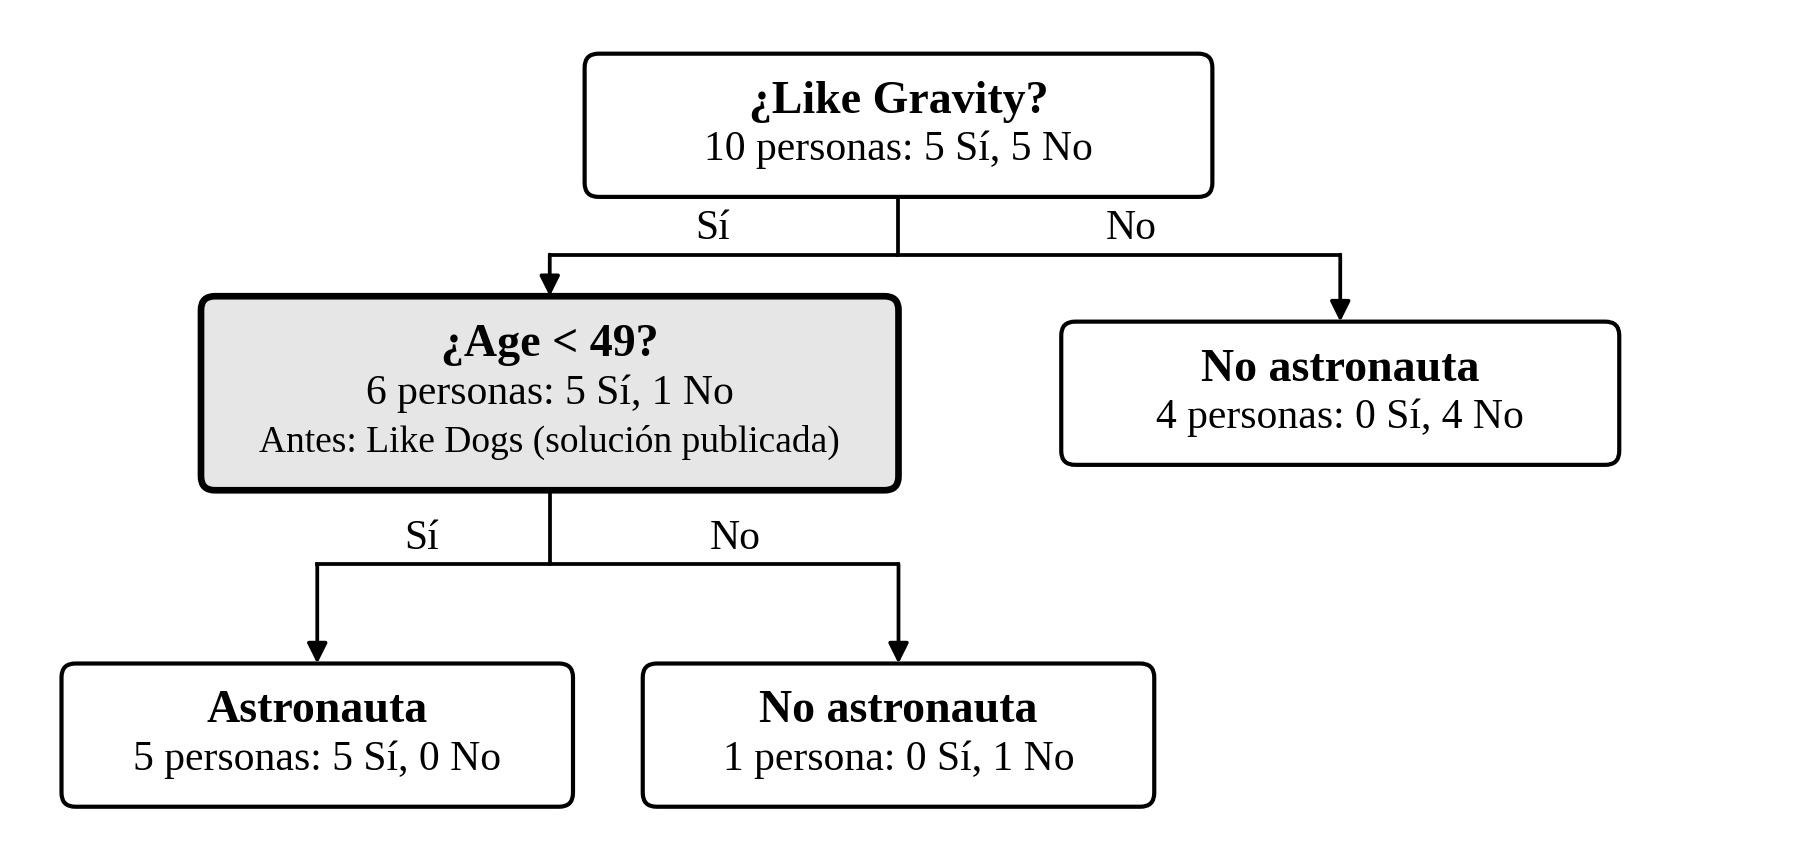

*Figura 1. Árbol corregido. Cada caja indica cuántas personas llegan al nodo y cuántas son astronautas (Sí) y no astronautas (No); el nodo resaltado es el que cambia respecto a la solución publicada.*

$${Gini}_{\text{final}} = \frac{4}{10}(0) + \frac{5}{10}(0) + \frac{1}{10}(0) = 0$$

Justificación: la raíz no cambia; lo que cambia es la segunda pregunta, Age \< 49 en lugar de Like Dogs. Con solo dos preguntas quedan tres hojas puras: clasifica bien los 10 datos y es más simple que el árbol publicado, que necesitaba tres preguntas.

### Errores comunes

1.  No verificar el balance: los conteos Sí/No de los hijos deben sumar los del padre. Con esa sola revisión se detectan los tres errores.
2.  Poner umbrales entre valores repetidos. Los umbrales van entre valores distintos consecutivos; con edades repetidas hay menos umbrales que datos.
3.  No recalcular todo en cada nodo nuevo. Los umbrales y conteos del segundo nivel se calculan solo con los datos que llegan a ese nodo.
4.  Confundir Gini ponderado con reducción de impureza: se busca el menor Gini ponderado, que es el mayor $\Delta I$.

## Demostración 8. AdaBoost: de dónde salen $a_{i}$, los pesos y $Z_{i}$

Todas las fórmulas del Algoritmo 5.1 salen de minimizar una sola función, la pérdida exponencial $\sum_{n}^{}\exp\left( - y_{n}F\left( x_{n} \right) \right)$, agregando un clasificador por ronda. De ahí resultan $a_{i} = \frac{1}{2}\ln\left( \left( 1 - P_{i} \right)/P_{i} \right)$, la regla que sube el peso de los datos fallados y $Z_{i} = 2\sqrt{P_{i}\left( 1 - P_{i} \right)}$. El error de entrenamiento queda acotado por el producto de los $Z_{i}$, que cae exponencialmente.

### Qué se pide

Demostrar el clasificador binario de AdaBoost y su algoritmo. Con $N$ datos $\left( y_{n},x_{n} \right)$ y etiquetas $y_{n} \in \{ - 1,1\}$:

$$f(x) = \operatorname{sgn}\{ F(x)\}\ \ \text{(ec. 5.2)},\quad\quad F(x): = \sum_{k = 1}^{K}a_{k}\,\phi\left( x;\theta_{k} \right)\ \ \text{(ec. 5.3)},\quad\quad\phi\left( x;\theta_{k} \right) \in \{ - 1,1\}$$

Y explicar de dónde salen las fórmulas del Algoritmo 5.1:

$$a_{i} = \frac{1}{2}\ln\left( \frac{1 - P_{i}}{P_{i}} \right),\quad\quad\omega_{n}^{(i + 1)} = \frac{\omega_{n}^{(i)}\exp\left( - y_{n}\, a_{i}\,\phi\left( x_{n};\theta_{i} \right) \right)}{Z_{i}},\quad\quad Z_{i} = \sum_{n = 1}^{N}\omega_{n}^{(i)}\exp\left( - y_{n}\, a_{i}\,\phi\left( x_{n};\theta_{i} \right) \right)$$

### Para qué sirve

AdaBoost muestra cómo combinar muchos clasificadores débiles, cada uno apenas mejor que lanzar una moneda, en uno fuerte. Es la idea base del boosting, que también usa XGBoost. La demostración prueba que las reglas del algoritmo no son arbitrarias: cada línea es la solución óptima de un subproblema bien definido.

### Intuición

Piensa en un panel de inspectores de calidad, cada uno con un criterio sencillo (por ejemplo, revisar solo el diámetro). Ninguno es muy bueno por sí solo. AdaBoost los pone a trabajar en fila:

1.  El primer inspector revisa todas las piezas con la misma atención.
2.  Las piezas que clasificó mal se marcan para revisión prioritaria: ganan peso.
3.  El siguiente inspector se ajusta para acertar sobre todo en las piezas marcadas.
4.  Se repite: cada inspector nuevo se concentra en lo que los anteriores no resolvieron.

Al final el panel vota, pero cada voto vale según la confiabilidad de quien lo emite. Ese peso del voto es $a_{i}$, las marcas de prioridad son los pesos $\omega_{n}$ y $Z_{i}$ es la normalización que hace que los pesos sumen 1, como las fracciones másicas de una mezcla.

### Símbolos

| **Símbolo** | **Qué es** |
|-----------------|-------------------------------------------------------|
| $y_{n} \in \{ - 1, + 1\}$ | Etiqueta real del dato $n$ |
| $\phi\left( x;\theta_{k} \right) \in \{ - 1, + 1\}$ | Clasificador base de la ronda $k$, por ejemplo un árbol de una sola pregunta |
| $a_{k}$ | Peso del voto del clasificador $k$ |
| $F(x)$ | Suma ponderada de votos; $\operatorname{sgn}\, F(x)$ es la decisión final |
| $\omega_{n}^{(i)}$ | Peso del dato $n$ en la ronda $i$ |
| $P_{i}$ | Error ponderado de la ronda $i$: suma de los pesos de los datos mal clasificados |
| $Z_{i}$ | Constante de normalización de los pesos |
| $y_{n}\,\phi\left( x_{n} \right)$ | Vale $+ 1$ si el clasificador acierta y $- 1$ si falla |

### Parte A. Derivación de las fórmulas

**Paso 1. La función que AdaBoost minimiza.**

Objetivo: fijar el criterio del que se derivan todas las reglas.

$$J = \sum_{n = 1}^{N}\exp\left( - y_{n}F\left( x_{n} \right) \right)$$

Justificación: si $y_{n}$ y $F\left( x_{n} \right)$ tienen el mismo signo (acierto), el exponente es negativo y el costo es pequeño; si tienen signo distinto (error), el costo crece exponencialmente. Castiga mucho los errores cometidos con seguridad. Además, como $e^{- z} \geq 1$ cuando $z \leq 0$, $J$ es una cota superior del número de errores (se usa en el Paso 9).

**Paso 2. Construir** $F$ **de a un término por ronda.**

Objetivo: convertir un problema difícil (optimizar todos los clasificadores a la vez) en una sucesión de problemas sencillos.

$$F_{i}(x) = F_{i - 1}(x) + a\,\phi(x;\theta),\quad\quad\left( a_{i},\theta_{i} \right) = \arg\min _{a,\,\theta}\sum_{n = 1}^{N}\exp\left( - y_{n}\left( F_{i - 1}\left( x_{n} \right) + a\,\phi\left( x_{n};\theta \right) \right) \right)$$

Justificación: es una estrategia por etapas y voraz: los clasificadores anteriores quedan fijos y solo se ajusta el nuevo. Es como dimensionar un sistema agregando un componente a la vez sin rediseñar los ya instalados.

**Paso 3. Aparecen los pesos.**

Objetivo: separar lo que ya está fijo de lo que se va a optimizar.

$$\exp\left( - y_{n}\left( F_{i - 1}\left( x_{n} \right) + a\,\phi_{n} \right) \right) = \underset{\propto \ \omega_{n}^{(i)}}{\underbrace{\exp\left( - y_{n}F_{i - 1}\left( x_{n} \right) \right)}} \cdot \exp\left( - y_{n}\, a\,\phi_{n} \right)$$

$$J(a,\theta) = \sum_{n = 1}^{N}\omega_{n}^{(i)}\exp\left( - y_{n}\, a\,\phi\left( x_{n};\theta \right) \right),\quad\quad\sum_{n}^{}\omega_{n}^{(i)} = 1$$

Justificación: la exponencial de una suma es el producto de las exponenciales. El primer factor no depende de $(a,\theta)$, así que actúa como un peso fijo del dato $n$. Ese peso es grande si los clasificadores anteriores fallaron con el dato $n$: son las marcas de prioridad. Los pesos se normalizan para sumar 1; multiplicar $J$ por una constante no cambia dónde está su mínimo.

**Paso 4. Separar aciertos y errores.**

Objetivo: escribir $J$ con un solo número, el error ponderado $P$.

$$y_{n}\,\phi\left( x_{n};\theta \right) = \left\{ \begin{matrix}
 + 1 & \text{acierto} \\
 - 1 & \text{error}
\end{matrix} \right. \quad \Rightarrow \quad J = e^{- a}\sum_{\text{aciertos}}^{}\omega_{n}^{(i)} + e^{a}\sum_{\text{errores}}^{}\omega_{n}^{(i)}$$

$$P = \sum_{n = 1}^{N}\omega_{n}^{(i)}\,\mathbb{I}\left\lbrack y_{n} \neq \phi\left( x_{n};\theta \right) \right\rbrack\quad \Rightarrow \quad J = e^{- a}(1 - P) + e^{a}P$$

Justificación: como las etiquetas y las predicciones valen $\pm 1$, el exponente solo puede ser $- a$ o $+ a$. $P$ es el peso total de los datos fallados y, como los pesos suman 1, los aciertos pesan $1 - P$.

**Paso 5. Elegir** $\theta_{i}$ **(líneas 1 y 2 del algoritmo).**

Objetivo: saber cómo entrenar el clasificador nuevo.

$$J = e^{- a} + \left( e^{a} - e^{- a} \right)P$$

Justificación: se reorganiza el Paso 4. Si $a > 0$, el paréntesis es positivo, así que minimizar $J$ equivale a minimizar $P$. El mejor clasificador nuevo es el que tiene menor error ponderado: eso es “calcular el óptimo $\theta_{i}$ minimizando $P_{i}$”.

**Paso 6. Elegir** $a_{i}$ **(línea 3 del algoritmo).**

Objetivo: encontrar el peso óptimo del voto.

$$\frac{\partial J}{\partial a} = - e^{- a}\left( 1 - P_{i} \right) + e^{a}P_{i} = 0\quad \Rightarrow \quad e^{2a} = \frac{1 - P_{i}}{P_{i}}\quad \Rightarrow \quad a_{i} = \frac{1}{2}\ln\left( \frac{1 - P_{i}}{P_{i}} \right)\quad\quad$$

Justificación: con $\theta_{i}$ fijo, se deriva respecto a $a$ y se iguala a cero; se multiplica por $e^{a}$, se toma logaritmo y se divide entre 2. La segunda derivada, $e^{- a}\left( 1 - P_{i} \right) + e^{a}P_{i}$, es positiva, así que es un mínimo. Lectura: si $P_{i}$ es pequeño, $a_{i}$ es grande (voto fuerte); si $P_{i} = 1/2$ (una moneda), $a_{i} = 0$ (voto nulo). Por eso se exige $P_{i} < 1/2$, que equivale a $a_{i} > 0$.

**Paso 7. Actualizar y normalizar los pesos (líneas 4 a 8).**

Objetivo: obtener los pesos de la ronda siguiente.

$$\exp\left( - y_{n}F_{i}\left( x_{n} \right) \right) = \exp\left( - y_{n}F_{i - 1}\left( x_{n} \right) \right) \cdot \exp\left( - y_{n}\, a_{i}\,\phi\left( x_{n};\theta_{i} \right) \right)$$

$$\omega_{n}^{(i + 1)} = \omega_{n}^{(i)} \times \left\{ \begin{matrix}
e^{- a_{i}} = \sqrt{P_{i}/\left( 1 - P_{i} \right)} & \text{acierto: el peso baja} \\
e^{a_{i}} = \sqrt{\left( 1 - P_{i} \right)/P_{i}} & \text{error: el peso sube}
\end{matrix} \right.$$

$$Z_{i} = \left( 1 - P_{i} \right)\, e^{- a_{i}} + P_{i}\, e^{a_{i}} = 2\sqrt{P_{i}\left( 1 - P_{i} \right)},\quad\quad\omega_{n}^{(i + 1)} \leftarrow \frac{\omega_{n}^{(i + 1)}}{Z_{i}}$$

Justificación: por el Paso 3, el peso de la ronda siguiente es el actual por un factor nuevo; eso es la línea 5.1. Al sustituir $a_{i}$, los aciertos se multiplican por un número menor que 1 y los errores por uno mayor que 1. $Z_{i}$ es la suma de los pesos nuevos (línea 5.2) y dividir entre él (línea 7.1) los deja sumando 1.

**Paso 8. Propiedad de reinicio: el clasificador anterior queda en 1/2.**

Objetivo: entender por qué cada ronda obliga a aprender algo nuevo.

$$\sum_{\text{errores}}^{}\omega_{n}^{(i + 1)} = \frac{P_{i}\, e^{a_{i}}}{Z_{i}} = \frac{P_{i}\sqrt{\left( 1 - P_{i} \right)/P_{i}}}{2\sqrt{P_{i}\left( 1 - P_{i} \right)}} = \frac{1}{2}$$

Justificación: después de reponderar, el clasificador recién agregado tiene error ponderado exactamente 1/2, el de una moneda. Volver a elegirlo no aportaría nada, así que el siguiente debe acertar en otros datos.

**Paso 9. El error de entrenamiento cae exponencialmente.**

Objetivo: demostrar que el procedimiento funciona.

$$\frac{1}{N}\sum_{n = 1}^{N}\mathbb{I}\left\lbrack \operatorname{sgn}F\left( x_{n} \right) \neq y_{n} \right\rbrack\  \leq \ \frac{1}{N}\sum_{n = 1}^{N}\exp\left( - y_{n}F\left( x_{n} \right) \right)\  = \ \prod_{i = 1}^{K}Z_{i}\  = \ \prod_{i = 1}^{K}2\sqrt{P_{i}\left( 1 - P_{i} \right)}$$

Justificación: si hay error, $- y_{n}F \geq 0$ y la exponencial vale al menos 1, así que la indicadora queda por debajo. La igualdad sale de desenrollar el Paso 7 desde $\omega^{(1)} = 1/N$: $\omega_{n}^{(K + 1)} = \exp\left( - y_{n}F\left( x_{n} \right) \right)/\left( N\prod Z_{i} \right)$, y como esos pesos suman 1, se obtiene la expresión. Cada $Z_{i}$ es menor que 1 si $P_{i} \neq 1/2$, así que el producto cae rápido.

**Paso 10. Por qué la decisión final usa el signo.**

Objetivo: justificar la ec. 5.2.

$$E\left\lbrack e^{- yF(x)} \mid x \right\rbrack = P(y = 1 \mid x)\, e^{- F} + P(y = - 1 \mid x)\, e^{F}\quad \Rightarrow \quad F^{\star}(x) = \frac{1}{2}\ln\frac{P(y = 1 \mid x)}{P(y = - 1 \mid x)}$$

Justificación: se deriva respecto a $F$, se iguala a cero y se despeja, igual que con $a_{i}$. $F^{\star}$ es positiva justo cuando $P(y = 1 \mid x) > P(y = - 1 \mid x)$, así que su signo es la regla de Bayes de la Demostración 1. AdaBoost aproxima $F^{\star}$ con la suma de votos; por eso tomar $\operatorname{sgn}\, F$ es la decisión correcta.

### Parte B. El Algoritmo 5.1, línea por línea

Cada ronda tiene cuatro movimientos en el mismo orden: entrenar, calificar, reponderar y normalizar. Cuando se cumple el criterio de parada, el panel vota.

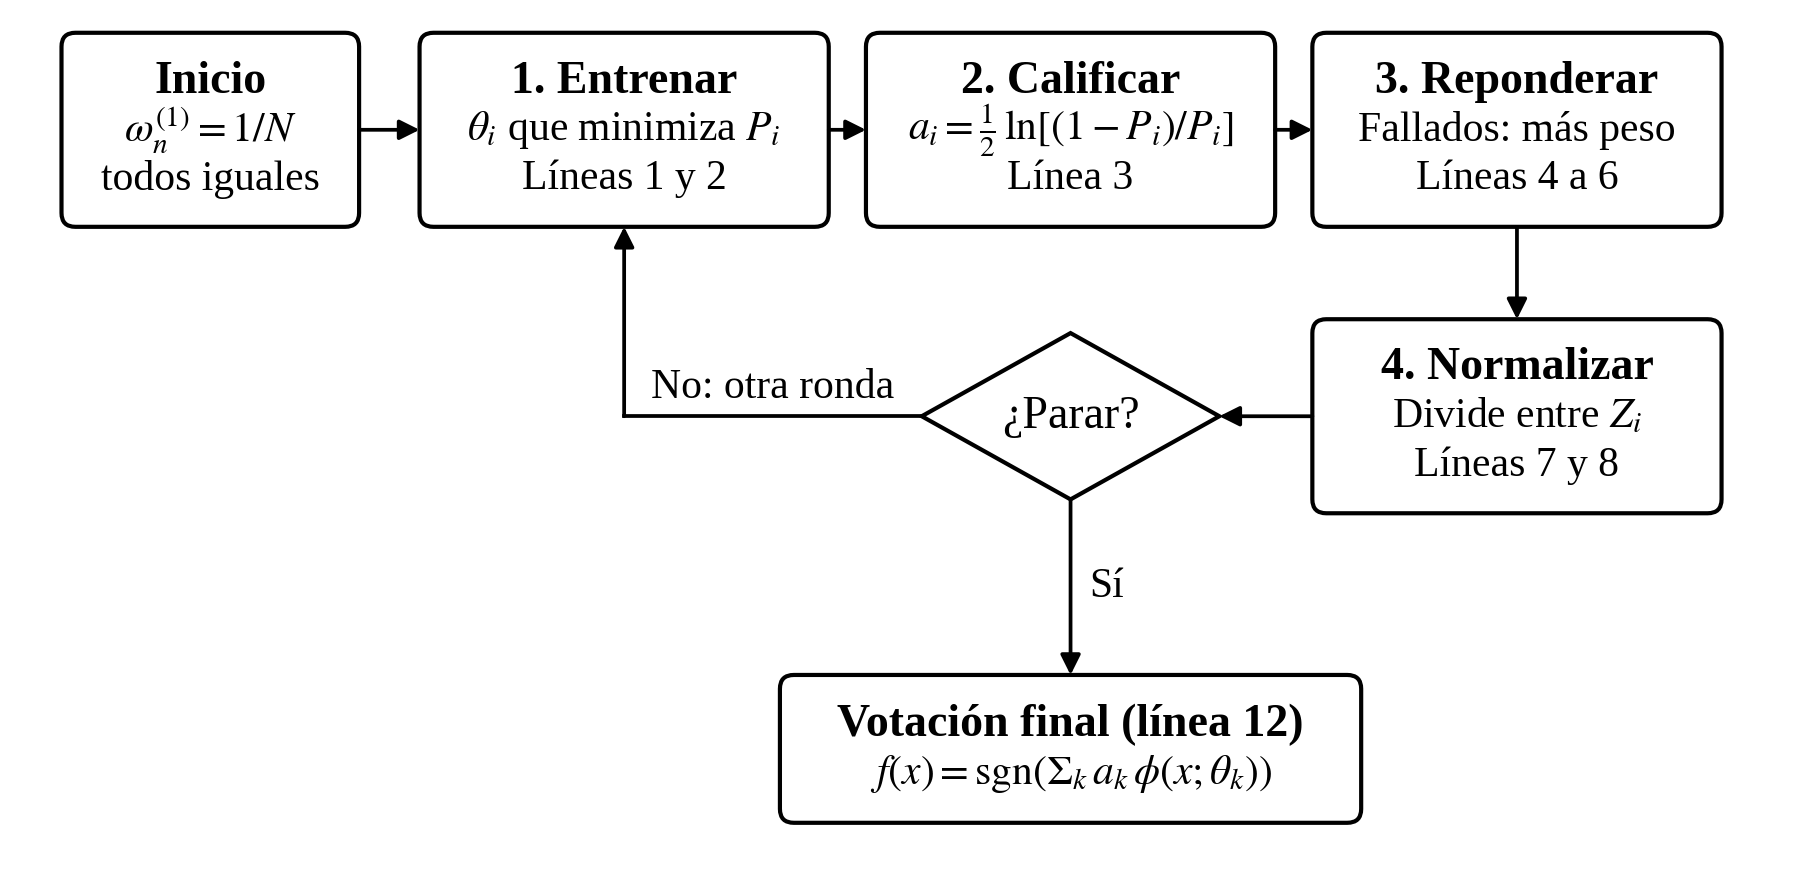

*Figura 2. Ciclo del Algoritmo 5.1. Los cuatro pasos se repiten en cada ronda; la votación de la línea 12 se ejecuta una sola vez, cuando se cumple el criterio de parada.*

| **Línea** | **Instrucción** | **Qué hace** | **De dónde sale** |
|--------|------------------------|--------------------|---------------------|
| Inicio 1 | $\omega_{n}^{(1)} = 1/N$, $n = 1,\ldots,N$ | Todos los datos pesan igual | $F_{0} = 0$ da $e^{0} = 1$ para todos; normalizado, $1/N$ |
| Inicio 2 | $i = 1$ | Contador de rondas | Notación del algoritmo |
| 1 | $\theta_{i} = \arg\min P_{i}$ | Entrena el clasificador base con los pesos actuales | Paso 5 |
| 2 | $P_{i} = \sum_{n}^{}\omega_{n}^{(i)}\,\mathbb{I}\left\lbrack y_{n} \neq \phi\left( x_{n};\theta_{i} \right) \right\rbrack$ | Error ponderado del clasificador nuevo | Paso 4 |
| 3 | $a_{i} = \frac{1}{2}\ln\left( \left( 1 - P_{i} \right)/P_{i} \right)$ | Peso de su voto | Paso 6 |
| 4 | $Z_{i} = 0$ | Inicia el acumulador | Necesario para la línea 5.2 |
| 5, 5.1, 5.2 | $\omega_{n}^{(i + 1)} = \omega_{n}^{(i)}e^{- y_{n}a_{i}\phi\left( x_{n};\theta_{i} \right)}$; $Z_{i} = Z_{i} + \omega_{n}^{(i + 1)}$ | Sube el peso de los fallados, baja el de los acertados y suma | Paso 7 |
| 7, 7.1 | $\omega_{n}^{(i + 1)} = \omega_{n}^{(i + 1)}/Z_{i}$ | Normaliza: los pesos vuelven a sumar 1 | Paso 7 |
| 9 | $K = i$ | Registra cuántos clasificadores tiene el panel | Notación del algoritmo |
| 10 | $i = i + 1$ | Pasa a la siguiente ronda | Notación del algoritmo |
| 11 | Until criterio de parada | Detiene el ciclo | Número fijo de rondas, $P_{i} \geq 1/2$ o error de prueba que empieza a subir |
| 12 | $f( \cdot ) = \operatorname{sgn}\left( \sum_{k}^{}a_{k}\phi\left( \cdot ;\theta_{k} \right) \right)$ | Votación ponderada final | Paso 10 |

Se necesitan dos ciclos For porque $Z_{i}$ solo se conoce cuando termina el primero: el primero calcula los pesos sin normalizar y los va sumando, y el segundo divide entre esa suma. El orden de las líneas tampoco es arbitrario: $a_{i}$ depende de $P_{i}$, los pesos dependen de $a_{i}$ y $Z_{i}$ depende de todos los pesos. Si $P_{i} = 0$, $a_{i}$ sería infinito; en la práctica se detiene el algoritmo o se impone un $P_{i}$ mínimo.

### Comprobación numérica: tres rondas a mano

Seis datos sobre una recta, $x = 1,2,3,4,5,6$, con etiquetas $y = ( + 1, + 1, - 1, - 1, + 1, - 1)$. El clasificador base es un umbral de una sola pregunta: si $x < c$, predice $s$; si no, predice $- s$. En cada ronda se elige el umbral de menor $P_{i}$.

| **Ronda** | **Umbral elegido** | **Datos que falla** | $P_{i}$ | $a_{i}$ | $Z_{i} = 2\sqrt{P_{i}\left( 1 - P_{i} \right)}$ |
|--------|--------------|------------|----------|---------------|---------------|
| 1 | $x < 2.5$ predice $+ 1$ | $n = 5$ | $1/6 = 0.167$ | $\frac{1}{2}\ln 5 = 0.805$ | 0.745 |
| 2 | $x < 5.5$ predice $+ 1$ | $n = 3,4$ | 0.200 | $\frac{1}{2}\ln 4 = 0.693$ | 0.800 |
| 3 | $x < 4.5$ predice $- 1$ | $n = 1,2,6$ | 0.1875 | $\frac{1}{2}\ln(13/3) = 0.733$ | 0.781 |

| $n$ | $x$ | $y$ | $\omega^{(1)}$ | $\omega^{(2)}$ | $\omega^{(3)}$ | $\omega^{(4)}$ |
|------|------|---------|-------------|-------------|---------------|-------------|
| 1 | 1 | $+ 1$ | 0.167 | 0.100 | 0.0625 | 0.167 |
| 2 | 2 | $+ 1$ | 0.167 | 0.100 | 0.0625 | 0.167 |
| 3 | 3 | $- 1$ | 0.167 | 0.100 | 0.250 | 0.154 |
| 4 | 4 | $- 1$ | 0.167 | 0.100 | 0.250 | 0.154 |
| 5 | 5 | $+ 1$ | 0.167 | 0.500 | 0.3125 | 0.192 |
| 6 | 6 | $- 1$ | 0.167 | 0.100 | 0.0625 | 0.167 |

En la ronda 1 el dato 5 fue el único error y su peso pasa de 0.167 a 0.5. En cada ronda los datos fallados terminan sumando exactamente 0.5, como predice el Paso 8; por ejemplo, en la ronda 2, $0.25 + 0.25 = 0.5$.

| $n$ | $F\left( x_{n} \right) = 0.805\phi_{1} + 0.693\phi_{2} + 0.733\phi_{3}$ | $f\left( x_{n} \right) = \operatorname{sgn}\, F$ | $y_{n}$ | **¿Acierta?** |
|----|-------------------------------------|---------------|------|------------|
| 1 | $0.805 + 0.693 - 0.733 = 0.765$ | $+ 1$ | $+ 1$ | Sí |
| 2 | $0.805 + 0.693 - 0.733 = 0.765$ | $+ 1$ | $+ 1$ | Sí |
| 3 | $- 0.805 + 0.693 - 0.733 = - 0.845$ | $- 1$ | $- 1$ | Sí |
| 4 | $- 0.805 + 0.693 - 0.733 = - 0.845$ | $- 1$ | $- 1$ | Sí |
| 5 | $- 0.805 + 0.693 + 0.733 = 0.622$ | $+ 1$ | $+ 1$ | Sí |
| 6 | $- 0.805 - 0.693 + 0.733 = - 0.765$ | $- 1$ | $- 1$ | Sí |

Ningún umbral por sí solo clasifica bien los 6 datos (el mejor falla 1), pero el panel de tres acierta todos. La cota del Paso 9 también se cumple: error de entrenamiento $0 \leq \prod Z_{i} = 0.745 \times 0.800 \times 0.781 = 0.466$.

### Errores comunes

1.  Leer la línea 3 como $\ln\left( 1 - P_{i} \right)$ dividido entre $P_{i}$. El logaritmo es de todo el cociente.
2.  Usar un clasificador base con $P_{i} \geq 1/2$. Su voto sería nulo o negativo; el algoritmo exige clasificadores mejores que una moneda.
3.  Olvidar normalizar. Sin $Z_{i}$, $P_{i}$ deja de estar entre 0 y 1 y la fórmula de $a_{i}$ pierde sentido.
4.  Seguir agregando rondas hasta error de entrenamiento cero. AdaBoost puede sobreajustar con datos ruidosos; conviene detenerse cuando el error en un conjunto de prueba empieza a subir.

**Observación sobre las notas.** En el Algoritmo 5.1 hay dos detalles:

1.  La línea 3 aparece como $a_{i} = 1/2\left\lbrack \ln\left( 1 - P_{i} \right)/P_{i} \right\rbrack$, que se puede leer como $\ln\left( 1 - P_{i} \right)$ dividido entre $P_{i}$. Debe ser $a_{i} = \frac{1}{2}\ln\left( \left( 1 - P_{i} \right)/P_{i} \right)$.
2.  La inicialización dice $\omega_{n}^{(1)} = 1/N,\ i = 1,\ldots,N$. El índice de los datos es $n$; la letra $i$ se reserva para la ronda.